# 3D U-Net (MONAI) for Glioma Segmentation – corrected baseline

## Purpose

This notebook trains the **MONAI 3D U-Net baseline** with exactly the same pipeline as the
**Swin UNETR** notebook, so that the two models differ **only in the architecture**.

The architecture is unchanged from the baseline notebook: `monai.networks.nets.UNet`,
channels 16-32-64-128, strides 2-2-2, 2 residual units per level, instance normalization
(≈ 1.19 M parameters). The model is wrapped in `GliomaMONAIUNet` (attribute `network`), as in
the baseline and MAE notebooks, so their checkpoints and MAE weights can be loaded directly.

### Identical to the Swin UNETR notebook

| Element | Value |
|---|---|
| Patients | `segmentation_manifest.csv` (1180: train 826 / validation 177 / test 177) |
| Cross-validation | the 5 folds of `5fold_manifest.csv` on the 1003 development patients (KFold, seed 42), test kept aside |
| Pre-processing | percentile clipping 0.5–99.5 + z-score on non-zero voxels, labels {0,1,2,4} → {0,1,2,3} |
| Patch sampling | 64 × 64 × 64, 2 patches/patient/epoch, 75% centered on tumor, samples shuffled individually |
| Augmentation | random flips, 90° rotations (axial plane), per-modality intensity scale/shift |
| Loss | 0.5 Cross-Entropy + 0.5 soft Dice (foreground) |
| Metrics during training | Dice and IoU (mean over the 3 foreground classes), training **and** validation |
| Model selection | lowest validation loss, early stopping patience 10, max 50 epochs |
| Optimizer | AdamW, lr 1e-4, weight decay 1e-5, batch size 2, mixed precision |
| Validation inference | sliding window 64³, overlap 0.5, Gaussian blending (`INFERENCE_MODE`) |
| Final evaluation | per patient Dice, IoU, HD, HD95 for whole tumor (1a) and sub-regions (1b) |

### Training recipe

`LR_SCHEDULE = "constant"` and `GRAD_CLIP_NORM = None` reproduce the baseline recipe (fixed
learning rate, no clipping). With `LR_SCHEDULE = "warmup_cosine"` and `GRAD_CLIP_NORM = 1.0`
the U-Net is trained with exactly the same recipe as the Swin UNETR.

### What was fixed compared with the previous baseline notebook

| Problem | Fix |
|---|---|
| `nn.DataParallel` on 2 GPUs: RAM of the notebook process grows at every call until the kernel dies | one GPU for training (`USE_DATA_PARALLEL = False`); validation on 2 GPUs without DataParallel |
| NIfTI files re-read and re-normalized at every epoch (CPU bottleneck) | preprocessed cache on `/kaggle/tmp` (not on `/kaggle/working`, which is limited to ~20 GB), rebuilt in full-volume coordinates: identical patches and volumes, verified at every run |
| Validation crash (155 not divisible by 8) | sliding-window inference, or zero padding to a multiple of 8 with `INFERENCE_MODE = "full_volume"` |
| 4 validation workers, prefetch, pinned memory, per-worker volume cache, int64 masks | 2 validation workers, prefetch 1, no pinned memory, no in-memory cache |
| No resume, no time limit, history saved only at the end of a fold | `last` checkpoint and history after every epoch, automatic resume, time and memory budgets |
| Patches of the same patient grouped in the same batch | standard shuffling, as in the Swin UNETR |
| Folds regenerated instead of read | folds read from the shared `5fold_manifest.csv` (checked to be identical) |
| Training Dice/IoU not computed | computed, as required for the report curves |
| Checkpoint loaded into a DataParallel model; `visualize_prediction` missing | fixed |

**Kaggle settings:** GPU T4 × 2, Internet ON (to install MONAI).


## 1. Setup

Set `DEBUG_MODE`, `FOLDS_TO_RUN`, `RESUME_FROM` and the manifest paths in the configuration cell.

In [10]:
# ================================================================
# CELL 1 - IMPORT LIBRARIES
# ================================================================

import os
import gc
import sys
import json
import math
import time
import random
import warnings
import subprocess
import importlib.util
from pathlib import Path
from collections import Counter
import shutil
import multiprocessing as mp
import threading
import ctypes

NOTEBOOK_START_TIME = time.time()

# CPU memory allocator (glibc): at most 2 allocation arenas, plus a function that
# gives the freed memory back to the system. Only memory management: no effect on results.
try:
    _libc = ctypes.CDLL("libc.so.6")
    _libc.mallopt(-8, 2)   # M_ARENA_MAX = 2
except (OSError, AttributeError):
    _libc = None


def release_cpu_memory():
    """Python garbage collection + return freed heap memory to the OS."""
    gc.collect()
    if _libc is not None:
        _libc.malloc_trim(0)


# Set by the memory monitor when the RAM is almost full: the running epoch is
# interrupted cleanly instead of letting the kernel die.
MEMORY_EMERGENCY = threading.Event()

# MONAI provides the 3D U-Net and sliding-window inference
for module, package in {"monai": "monai"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import numpy as np
import pandas as pd
import nibabel as nib

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import StratifiedKFold, KFold
from scipy.ndimage import distance_transform_edt, binary_erosion

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

import monai
from monai.networks.nets import UNet
from monai.inferers import sliding_window_inference

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")
print("PyTorch:", torch.__version__, "| MONAI:", monai.__version__)

# ================================================================
# CELL 2 - GENERAL CONFIGURATION
# ================================================================

# -------------------------------
# Dataset paths (same as the Swin UNETR)
# -------------------------------

IMAGES_DIR = Path(
    "/kaggle/input/datasets/laurapitton/training-images/Training_images"
)

# MODIFICA questi percorsi con quelli effettivi dei manifest
MANIFEST_PATH = Path(
    "/kaggle/input/datasets/liviapantarotto/segmentation-manifest/segmentation_manifest.csv"
)

# Shared fold assignment (same file as the Swin UNETR). If found, the folds are read from here;
# otherwise they are regenerated with the same code and seed (KFold, seed 42).
SHARED_FOLD_MANIFEST_PATH = Path(
    "/kaggle/input/datasets/liviapantarotto/5foldmanifest/5fold_manifest.csv"
)

# -------------------------------
# Run mode
# -------------------------------
# DEBUG_MODE = True  -> quick end-to-end check (few patients, 2 epochs,
#                       separate output folder): use it after every change
# DEBUG_MODE = False -> real training

DEBUG_MODE = False

DEBUG_TRAIN_PATIENTS = 16
DEBUG_VAL_PATIENTS = 4
DEBUG_EPOCHS = 2

# -------------------------------
# Output directory
# -------------------------------

OUTPUT_DIR = Path(
    "/kaggle/working/glioma_3d_unet" + ("_debug" if DEBUG_MODE else "")
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

RESULTS_DIR = OUTPUT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# -------------------------------
# Resume from a previous session (optional)
# -------------------------------
# RESUME = True: add the output of the previous version of THIS notebook as input
# (Add Input -> Your Work -> this notebook); its folder is found automatically.
# RESUME = False: start from scratch.

RESUME = False

RESUME_FROM = None

if RESUME:

    RESUME_FROM = next(
        (p for pattern in [f"*/{OUTPUT_DIR.name}", f"*/*/{OUTPUT_DIR.name}",
                           f"*/*/*/{OUTPUT_DIR.name}", f"*/*/*/*/{OUTPUT_DIR.name}"]
         for p in Path("/kaggle/input").glob(pattern)),
        None
    )

    print("RESUME_FROM:", RESUME_FROM)

    assert RESUME_FROM is not None and (RESUME_FROM / "checkpoints").exists(), (
        f"Folder {OUTPUT_DIR.name} with checkpoints not found among the inputs"
    )

if RESUME_FROM is not None:

    RESUME_FROM = Path(RESUME_FROM)

    if not RESUME_FROM.exists():
        raise FileNotFoundError(f"RESUME_FROM not found: {RESUME_FROM}")

    for subfolder in ["checkpoints", "results"]:
        if (RESUME_FROM / subfolder).exists():
            shutil.copytree(
                RESUME_FROM / subfolder,
                OUTPUT_DIR / subfolder,
                dirs_exist_ok=True
            )

    print("Previous checkpoints and results copied from:", RESUME_FROM)

    for path in sorted(CHECKPOINT_DIR.glob("*.pth")):
        print("  ", path.name)

# -------------------------------
# Reproducibility
# -------------------------------

SEED = 42

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

# -------------------------------
# Device configuration
# -------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():

    print("Number of GPUs:", torch.cuda.device_count())

    for i in range(torch.cuda.device_count()):
        print(
            f"GPU {i}:",
            torch.cuda.get_device_name(i)
        )
else:
    print("WARNING: no GPU. Enable 'GPU T4 x2' in the Kaggle notebook settings.")

# -------------------------------
# Training parameters (identical to the Swin UNETR)
# -------------------------------

N_FOLDS = 5

# Folds trained in this session (e.g. [0] to compare models on one fold first)
FOLDS_TO_RUN = [1]

PATCH_SIZE = (64, 64, 64)

BATCH_SIZE = 2

# Only affect data-loading speed / memory, not the results
NUM_WORKERS = 4        # training patches (small)
VAL_NUM_WORKERS = 2    # validation full volumes (~0.3 GB per batch)

# RAM / shared-memory log interval (seconds)
MEMORY_LOG_SECONDS = 120

# Multi-GPU with nn.DataParallel. The total batch is the same (BATCH_SIZE), so this
# only changes speed and memory, not the results.
# False = 1 GPU: nn.DataParallel made the RAM of the notebook process grow by ~10 GB
# per epoch (kernel died at epoch 3 and 5).
USE_DATA_PARALLEL = False

# Validation and final evaluation on several GPUs WITHOUT nn.DataParallel: the volumes
# of a batch are predicted in parallel, one per GPU (same predictions, ~1.8x faster).
# Training always uses one GPU. 1 = everything on one GPU (as in v5).
VALIDATION_GPUS = 2

# Training stops cleanly (checkpoints already saved) before an epoch that would
# push the RAM above this percentage; above EMERGENCY_RAM_PERCENT the running
# epoch is interrupted. In both cases the session ends normally and can be resumed.
MAX_RAM_PERCENT = 85
EMERGENCY_RAM_PERCENT = 93

# Give freed CPU memory back to the system every N batches
TRIM_EVERY_TRAIN_BATCHES = 100
TRIM_EVERY_VAL_BATCHES = 10

MAX_EPOCHS = 50

LEARNING_RATE = 1e-4

WEIGHT_DECAY = 1e-5

PATIENCE = 10

MODALITIES = [
    "FLAIR",
    "T1",
    "T1CE",
    "T2"
]

NUM_INPUT_CHANNELS = 4
NUM_CLASSES = 4

# -------------------------------
# MONAI 3D U-Net (architecture unchanged from the baseline notebook)
# -------------------------------

MODEL_NAME = "3D U-Net (MONAI)"

BASE_CHANNELS = 16           # channels 16 -> 32 -> 64 -> 128
NUM_RES_UNITS = 2            # residual units per level
UNET_STRIDES = (2, 2, 2)     # 3 downsamplings: spatial sizes must be divisible by 8

# -------------------------------
# Training recipe
# -------------------------------
# "constant" + None = baseline recipe (fixed learning rate, no clipping).
# "warmup_cosine" + 1.0 = exactly the same recipe as the Swin UNETR.

LR_SCHEDULE = "constant"     # "constant" or "warmup_cosine"
WARMUP_EPOCHS = 5            # only used by "warmup_cosine"
GRAD_CLIP_NORM = None        # None = no gradient clipping

# -------------------------------
# Inference on full volumes (validation and final evaluation)
# -------------------------------
# "sliding_window": same inference as the Swin UNETR (64^3 windows, overlap 0.5,
#                   Gaussian blending), so only the architecture differs.
# "full_volume":    whole volume in one pass, zero-padded to a multiple of 8.

INFERENCE_MODE = "sliding_window"

SW_OVERLAP = 0.5
SW_BATCH_SIZE = 8
SW_MODE = "gaussian"

# cuDNN chooses the fastest convolution algorithms for the fixed input sizes (speed only)
torch.backends.cudnn.benchmark = True

# -------------------------------
# Speed and session management (no effect on the results)
# -------------------------------

# Scratch disk (not saved with the notebook output): rebuilt at every session
CACHE_DIR = Path("/kaggle/tmp/glioma_cache")

# float16 halves the disk space (rounding ~5e-4); float32 = bit-identical
CACHE_DTYPE = np.float16

CACHE_PROCESSES = 4

# Training stops cleanly before starting an epoch that would exceed this budget
MAX_SESSION_HOURS = 10.5

# Final evaluation (HD/HD95 on every validation patient) is skipped,
# and can be run in the next session, if the session is older than this
EVALUATION_DEADLINE_HOURS = 11.0

# The U-Net downsamples 3 times -> every patch side must be divisible by 8
assert all(size % 8 == 0 for size in PATCH_SIZE), (
    "The 3D U-Net requires PATCH_SIZE divisible by 8."
)
assert INFERENCE_MODE in ("sliding_window", "full_volume")
assert LR_SCHEDULE in ("constant", "warmup_cosine")



def use_multi_gpu():
    return USE_DATA_PARALLEL and torch.cuda.is_available() and torch.cuda.device_count() > 1


print("GPUs used by the model:", 2 if use_multi_gpu() else 1,
      "(nn.DataParallel)" if use_multi_gpu() else "")

print("Model:", MODEL_NAME, "| LR schedule:", LR_SCHEDULE,
      "| gradient clipping:", GRAD_CLIP_NORM, "| inference:", INFERENCE_MODE)

if DEBUG_MODE:

    MAX_EPOCHS = DEBUG_EPOCHS

    print(
        f"\nDEBUG MODE: {DEBUG_TRAIN_PATIENTS} training / {DEBUG_VAL_PATIENTS} "
        f"validation patients per fold, {MAX_EPOCHS} epochs, output in {OUTPUT_DIR}"
    )

print("\nConfiguration completed.")


Libraries imported successfully.
PyTorch: 2.11.0+cu130 | MONAI: 1.6.1
Device: cuda
Number of GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
GPUs used by the model: 1 
Model: 3D U-Net (MONAI) | LR schedule: constant | gradient clipping: None | inference: sliding_window

Configuration completed.


## 2. Data: manifest, split, pre-processing, augmentation

All cells in this section are **identical to the Swin UNETR**, except the last one (preprocessed cache), which only changes how fast the same data are read.

In [11]:
# ================================================================
# CELL 3 - CHECK DATASET PATHS
# ================================================================

print("Checking dataset paths...\n")

print(
    "MRI directory:",
    IMAGES_DIR.exists()
)

print(
    "Manifest file:",
    MANIFEST_PATH.exists()
)

if not IMAGES_DIR.exists():
    raise FileNotFoundError(
        f"MRI directory not found: {IMAGES_DIR}"
    )

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"Manifest not found: {MANIFEST_PATH}\n"
        "Please update MANIFEST_PATH in Cell 2."
    )

print("\nAll required paths are available.")

# ================================================================
# CELL 4 - LOAD SEGMENTATION MANIFEST
# ================================================================

manifest = pd.read_csv(MANIFEST_PATH)

print("Manifest loaded successfully.")
print("Number of patients:", len(manifest))

print("\nAvailable columns:")
print(manifest.columns.tolist())

display(manifest.head())

# ================================================================
# CELL 5 - VALIDATE MANIFEST
# ================================================================

REQUIRED_COLUMNS = [
    "patient_folder",
    "FLAIR_path",
    "T1_path",
    "T1CE_path",
    "T2_path",
    "MASK_path",
    "split",
    "Cohort ID"
]

# Check required columns
missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in manifest.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in manifest: {missing_columns}"
    )

# Check split distribution
print("Original split distribution:")
print(manifest["split"].value_counts(dropna=False))

print("\nPatients per cohort:")
print(manifest["Cohort ID"].value_counts(dropna=False))

# Check duplicate patients
print(
    "\nDuplicate patient folders:",
    manifest["patient_folder"].duplicated().sum()
)

# Check missing values in essential columns
print("\nMissing values:")
display(
    manifest[REQUIRED_COLUMNS].isna().sum()
)

# Check expected patient counts
assert len(manifest) == 1180, (
    f"Expected 1180 patients, found {len(manifest)}"
)

assert manifest["patient_folder"].is_unique, (
    "Duplicate patient folders detected."
)

print("\nManifest validation completed.")

Checking dataset paths...

MRI directory: True
Manifest file: True

All required paths are available.
Manifest loaded successfully.
Number of patients: 1180

Available columns:
['patient_key', 'patient_folder', 'Cohort ID', 'split', 'is_labeled', 'is_unlabeled', 'use_for_mae', 'use_for_segmentation', 'FLAIR', 'T1', 'T1CE', 'T2', 'ALL_MODALITIES_PRESENT', 'FLAIR_path', 'T1_path', 'T1CE_path', 'T2_path', 'MASK', 'MASK_path', 'MRI_COMBINATION']


,patient_key,patient_folder,Cohort ID,split,is_labeled,is_unlabeled,use_for_mae,use_for_segmentation,FLAIR,T1,T1CE,T2,ALL_MODALITIES_PRESENT,FLAIR_path,T1_path,T1CE_path,T2_path,MASK,MASK_path,MRI_COMBINATION
0,1,1,1,validation,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
1,10,10,2,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
2,1000,1000,8,test,True,False,False,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
3,1001,1001,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2
4,1002,1002,8,train,True,False,True,True,True,True,True,True,True,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,/kaggle/input/datasets/laurapitton/training-im...,True,/kaggle/input/datasets/laurapitton/training-im...,FLAIR + T1 + T1CE + T2


Original split distribution:
split
train         826
validation    177
test          177
Name: count, dtype: int64

Patients per cohort:
Cohort ID
8    378
4    348
7    233
5     94
6     65
2     33
3     25
1      4
Name: count, dtype: int64

Duplicate patient folders: 0

Missing values:


patient_folder    0
FLAIR_path        0
T1_path           0
T1CE_path         0
T2_path           0
MASK_path         0
split             0
Cohort ID         0
dtype: int64


Manifest validation completed.


In [12]:
# ================================================================
# CELL 6 - DEVELOPMENT AND TEST SET
# ================================================================

development_df = manifest[
    manifest["split"].isin(["train", "validation"])
].copy().reset_index(drop=True)

test_df = manifest[
    manifest["split"] == "test"
].copy().reset_index(drop=True)

print("Development patients:", len(development_df))
print("Independent test patients:", len(test_df))

assert len(development_df) == 1003
assert len(test_df) == 177

# Verify patient-level separation
development_ids = set(
    development_df["patient_folder"].astype(str)
)

test_ids = set(
    test_df["patient_folder"].astype(str)
)

assert development_ids.isdisjoint(test_ids), (
    "Data leakage detected between development and test sets!"
)

print("\nNo patient overlap between development and test.")

# ================================================================
# CELL 7 - VERIFY MRI AND MASK FILES
# ================================================================

PATH_COLUMNS = [
    "FLAIR_path",
    "T1_path",
    "T1CE_path",
    "T2_path",
    "MASK_path"
]

missing_files = []

for _, row in manifest.iterrows():

    patient = row["patient_folder"]

    for column in PATH_COLUMNS:

        path = row[column]

        if not isinstance(path, str) or not Path(path).is_file():

            missing_files.append({
                "patient": patient,
                "column": column,
                "path": path
            })

missing_files_df = pd.DataFrame(missing_files)

print("Missing files:", len(missing_files_df))

if len(missing_files_df) > 0:

    display(missing_files_df.head(20))

    raise FileNotFoundError(
        "Some MRI or mask files are missing. "
        "Check the manifest paths before training."
    )

print("\nAll MRI volumes and masks are accessible.")


Development patients: 1003
Independent test patients: 177

No patient overlap between development and test.
Missing files: 0

All MRI volumes and masks are accessible.


In [13]:
# ================================================================
# CELL 8 - 5-FOLD CROSS-VALIDATION SPLITS (same folds as the Swin UNETR)
# ================================================================

# Work only with the development set
cv_df = development_df.copy().reset_index(drop=True)

if SHARED_FOLD_MANIFEST_PATH.exists():

    shared_folds = pd.read_csv(SHARED_FOLD_MANIFEST_PATH)[["patient_folder", "fold"]]

    cv_df = cv_df.merge(
        shared_folds,
        on="patient_folder",
        how="left"
    )

    assert cv_df["fold"].notna().all(), (
        "Some development patients have no fold in the shared fold manifest."
    )

    cv_df["fold"] = cv_df["fold"].astype(int)

    print("Folds loaded from the shared fold manifest (identical to the Swin UNETR).")

else:

    print(
        "Shared fold manifest not found: folds regenerated with the same code "
        "and seed as the 3D U-Net baseline."
    )

    stratification_labels = (
        cv_df["Cohort ID"]
        .fillna("Unknown")
        .astype(str)
    )

    if stratification_labels.value_counts().min() >= N_FOLDS:

        print("Using StratifiedKFold by Cohort ID.")

        cv = StratifiedKFold(
            n_splits=N_FOLDS,
            shuffle=True,
            random_state=SEED
        )

        split_iterator = cv.split(
            cv_df,
            stratification_labels
        )

    else:

        print("At least one cohort has fewer than 5 patients: using standard KFold.")

        cv = KFold(
            n_splits=N_FOLDS,
            shuffle=True,
            random_state=SEED
        )

        split_iterator = cv.split(cv_df)

    cv_df["fold"] = -1

    for fold, (_, val_indices) in enumerate(split_iterator):
        cv_df.loc[val_indices, "fold"] = fold

# Verify assignments
assert (cv_df["fold"] >= 0).all()
assert cv_df["patient_folder"].is_unique

# Save fold assignments used by this notebook
FOLD_MANIFEST_PATH = OUTPUT_DIR / "5fold_manifest.csv"

cv_df.to_csv(
    FOLD_MANIFEST_PATH,
    index=False
)

print("\nPatients assigned to each fold:")
print(cv_df["fold"].value_counts().sort_index())

# ================================================================
# CELL 9 - VERIFY FOLD DISTRIBUTION
# ================================================================

print("\nCohort distribution per fold:\n")

display(
    pd.crosstab(
        cv_df["fold"],
        cv_df["Cohort ID"]
    )
)

# ================================================================
# CELL 10 - VERIFY CROSS-VALIDATION INTEGRITY
# ================================================================

all_validation_ids = []

for fold in range(N_FOLDS):

    val_fold = cv_df[cv_df["fold"] == fold]
    train_fold = cv_df[cv_df["fold"] != fold]

    train_ids = set(train_fold["patient_folder"].astype(str))
    val_ids = set(val_fold["patient_folder"].astype(str))

    assert train_ids.isdisjoint(val_ids), (
        f"Leakage detected in fold {fold}"
    )

    all_validation_ids.extend(val_ids)

    print(
        f"Fold {fold}: "
        f"Train = {len(train_ids)}, "
        f"Validation = {len(val_ids)}"
    )

# Every development patient must be validation exactly once
assert len(all_validation_ids) == len(set(all_validation_ids))
assert set(all_validation_ids) == set(cv_df["patient_folder"].astype(str))

# Test set must remain excluded
assert set(cv_df["patient_folder"].astype(str)).isdisjoint(
    set(test_df["patient_folder"].astype(str))
)

print("\nAll cross-validation integrity checks passed.")


Folds loaded from the shared fold manifest (identical to the Swin UNETR).

Patients assigned to each fold:
fold
0    201
1    201
2    201
3    200
4    200
Name: count, dtype: int64

Cohort distribution per fold:



Cohort ID,1,2,3,4,5,6,7,8
fold,,,,,,,,
0,1,8,5,61,15,8,39,64
1,1,7,2,62,26,9,29,65
2,1,6,4,56,15,16,32,71
3,1,1,3,59,7,16,52,61
4,0,6,7,58,17,6,46,60


Fold 0: Train = 802, Validation = 201
Fold 1: Train = 802, Validation = 201
Fold 2: Train = 802, Validation = 201
Fold 3: Train = 803, Validation = 200
Fold 4: Train = 803, Validation = 200

All cross-validation integrity checks passed.


In [14]:
# ================================================================
# CELL 11 - LABEL MAPPING AND PREPROCESSING CONFIGURATION
# ================================================================

# Original dataset labels -> consecutive training labels
LABEL_MAPPING = {
    0: 0,  # Background
    1: 1,  # Necrotic core
    2: 2,  # FLAIR signal hyperintensity
    4: 3   # Enhancing tumor
}

CLASS_NAMES = {
    0: "Background",
    1: "Necrotic core",
    2: "FLAIR signal hyperintensity",
    3: "Enhancing tumor"
}

# Normalization percentiles
LOWER_PERCENTILE = 0.5
UPPER_PERCENTILE = 99.5

# Patch sampling
SAMPLES_PER_PATIENT = 2
TUMOR_PATCH_PROBABILITY = 0.75

print("Label mapping:")
for original, training in LABEL_MAPPING.items():
    print(
        f"Original label {original} -> "
        f"Training label {training}: "
        f"{CLASS_NAMES[training]}"
    )

print("\nPatch size:", PATCH_SIZE)
print("Samples per patient:", SAMPLES_PER_PATIENT)

# ================================================================
# CELL 12 - MRI LOADING AND NORMALIZATION
# ================================================================

def normalize_mri(volume):
    """
    Percentile clipping followed by z-score normalization.
    Background voxels remain zero.
    """

    volume = np.asarray(
        volume,
        dtype=np.float32
    )

    nonzero_mask = volume != 0

    if not nonzero_mask.any():
        return np.zeros_like(volume, dtype=np.float32)

    values = volume[nonzero_mask]

    lower = np.percentile(
        values,
        LOWER_PERCENTILE
    )

    upper = np.percentile(
        values,
        UPPER_PERCENTILE
    )

    clipped = np.clip(
        volume,
        lower,
        upper
    )

    clipped_values = clipped[nonzero_mask]

    mean = clipped_values.mean()
    std = clipped_values.std()

    if std < 1e-8:
        normalized = np.zeros_like(volume, dtype=np.float32)
    else:
        normalized = (clipped - mean) / std

    normalized[~nonzero_mask] = 0

    return normalized.astype(np.float32)


def load_nifti_volume(path):
    """
    Load a NIfTI volume as a float32 NumPy array.
    """

    nii = nib.load(str(path))

    volume = nii.get_fdata(
        dtype=np.float32
    )

    return volume, nii


def load_patient_volumes(row):
    """
    Load and normalize the four MRI modalities.
    Load and remap the segmentation mask.
    """

    image_channels = []

    for modality in MODALITIES:

        path = row[f"{modality}_path"]

        volume, _ = load_nifti_volume(path)

        volume = normalize_mri(volume)

        image_channels.append(volume)

    # Shape: (4, X, Y, Z)
    image = np.stack(
        image_channels,
        axis=0
    )

    # Load segmentation mask
    mask, mask_nii = load_nifti_volume(
        row["MASK_path"]
    )

    # Verify spatial dimensions
    if image.shape[1:] != mask.shape:
        raise ValueError(
            f"Image/mask shape mismatch for "
            f"patient {row['patient_folder']}: "
            f"{image.shape[1:]} vs {mask.shape}"
        )

    # Verify original labels
    original_labels = set(
        np.unique(mask).astype(int)
    )

    unexpected_labels = (
        original_labels - set(LABEL_MAPPING.keys())
    )

    if unexpected_labels:
        raise ValueError(
            f"Unexpected labels for patient "
            f"{row['patient_folder']}: "
            f"{unexpected_labels}"
        )

    # Map original labels to consecutive classes
    mapped_mask = np.zeros(
        mask.shape,
        dtype=np.uint8
    )

    for original_label, training_label in LABEL_MAPPING.items():

        mapped_mask[
            mask == original_label
        ] = training_label

    return (
        image.astype(np.float32),
        mapped_mask,
        mask_nii
    )


print("MRI loading and normalization functions defined.")

Label mapping:
Original label 0 -> Training label 0: Background
Original label 1 -> Training label 1: Necrotic core
Original label 2 -> Training label 2: FLAIR signal hyperintensity
Original label 4 -> Training label 3: Enhancing tumor

Patch size: (64, 64, 64)
Samples per patient: 2
MRI loading and normalization functions defined.


In [15]:
# ================================================================
# CELL 13 - 3D PATCH EXTRACTION
# ================================================================

def extract_3d_patch(image, mask, patch_size, tumor_probability=0.75):
    """
    Extract a 3D patch from a multimodal MRI volume.

    image shape: (C, X, Y, Z)
    mask shape:  (X, Y, Z)
    """

    spatial_shape = mask.shape

    # Choose patch center
    tumor_coords = np.argwhere(mask > 0)

    use_tumor_center = (
        len(tumor_coords) > 0
        and random.random() < tumor_probability
    )

    if use_tumor_center:

        center = tumor_coords[
            random.randrange(len(tumor_coords))
        ]

    else:

        center = np.array([
            random.randrange(s)
            for s in spatial_shape
        ])

    # Pad volumes if smaller than requested patch
    pad_width = []

    for dim, patch_dim in zip(
        spatial_shape,
        patch_size
    ):

        total_pad = max(
            patch_dim - dim,
            0
        )

        before = total_pad // 2
        after = total_pad - before

        pad_width.append((before, after))

    image_pad = np.pad(
        image,
        [(0, 0)] + pad_width,
        mode="constant"
    )

    mask_pad = np.pad(
        mask,
        pad_width,
        mode="constant"
    )

    # Adjust center after padding
    center = center + np.array([
        p[0] for p in pad_width
    ])

    # Calculate patch boundaries
    starts = []

    for c, patch_dim, dim in zip(
        center,
        patch_size,
        mask_pad.shape
    ):

        start = int(c - patch_dim // 2)

        start = max(
            0,
            min(start, dim - patch_dim)
        )

        starts.append(start)

    slices = tuple(
        slice(start, start + patch_dim)
        for start, patch_dim in zip(
            starts,
            patch_size
        )
    )

    image_patch = image_pad[
        (slice(None),) + slices
    ]

    mask_patch = mask_pad[slices]

    return image_patch, mask_patch


print("3D patch extraction function defined.")

3D patch extraction function defined.


In [16]:
# ================================================================
# CELL 14 - DATA AUGMENTATION
# ================================================================

def augment_patch(image, mask):
    """
    Apply spatial and intensity augmentation.

    image: (C, X, Y, Z)
    mask:  (X, Y, Z)
    """

    # Random flips along spatial axes
    for axis in range(3):

        if random.random() < 0.5:

            image = np.flip(
                image,
                axis=axis + 1
            )

            mask = np.flip(
                mask,
                axis=axis
            )

    # Random 90-degree rotations in the first two axes
    k = random.randint(0, 3)

    image = np.rot90(
        image,
        k=k,
        axes=(1, 2)
    )

    mask = np.rot90(
        mask,
        k=k,
        axes=(0, 1)
    )

    # Per-modality intensity augmentation
    for channel in range(image.shape[0]):

        if random.random() < 0.5:

            scale = random.uniform(0.9, 1.1)
            shift = random.uniform(-0.1, 0.1)

            image[channel] = (
                image[channel] * scale + shift
            )

    # Ensure contiguous arrays (negative strides can break torch conversion)
    image = np.ascontiguousarray(
        image,
        dtype=np.float32
    )

    mask = np.ascontiguousarray(
        mask,
        dtype=np.int64
    )

    return image, mask


print("Data augmentation function defined.")

Data augmentation function defined.


In [17]:
# ================================================================
# CELL 15 - PYTORCH DATASET
# ================================================================

class Glioma3DDataset(Dataset):

    def __init__(
        self,
        dataframe,
        training=True,
        samples_per_patient=2
    ):

        self.df = dataframe.reset_index(drop=True)

        self.training = training

        self.samples_per_patient = (
            samples_per_patient if training else 1
        )

    def __len__(self):

        return (
            len(self.df) * self.samples_per_patient
        )

    def __getitem__(self, index):

        patient_index = (
            index // self.samples_per_patient
        )

        row = self.df.iloc[patient_index]

        # Load full MRI and mask
        image, mask, _ = load_patient_volumes(row)

        if self.training:

            image, mask = extract_3d_patch(
                image,
                mask,
                PATCH_SIZE,
                tumor_probability=TUMOR_PATCH_PROBABILITY
            )

            image, mask = augment_patch(
                image,
                mask
            )

        else:

            image = np.ascontiguousarray(
                image,
                dtype=np.float32
            )

            mask = np.ascontiguousarray(
                mask,
                dtype=np.int64
            )

        return {
            "image": torch.from_numpy(image),
            "mask": torch.from_numpy(mask),
            "patient_id": str(row["patient_folder"])
        }


print("Glioma3DDataset class defined.")

Glioma3DDataset class defined.


In [18]:
# ================================================================
# CELL 16 - PREPROCESSED CACHE (speed only: identical data)
# ================================================================
#
# The original pipeline reloads and re-normalizes 4 full NIfTI volumes + mask
# for EVERY training patch and EVERY validation volume: the CPU becomes the
# bottleneck and the GPU waits.
#
# Here each patient is preprocessed ONCE with the very same function
# (load_patient_volumes: clipping + z-score + label mapping) and stored on the
# scratch disk, cropped to the bounding box of the non-zero voxels.
# Everything outside the box is exactly zero in both image and mask, so:
#   - full volumes are rebuilt exactly (zero padding to 240 x 240 x 155);
#   - patches are extracted with the SAME random logic and in the SAME
#     full-volume coordinates as extract_3d_patch (same centers, same borders);
#   - augmentation, loss and metrics are unchanged.
# The only difference is float16 storage, verified by the equivalence check.


def get_fold_split(fold):
    """Training and validation patients of a fold (subsampled in DEBUG_MODE)."""

    train_df = cv_df[cv_df["fold"] != fold].copy().reset_index(drop=True)
    val_df = cv_df[cv_df["fold"] == fold].copy().reset_index(drop=True)

    if DEBUG_MODE:
        train_df = train_df.sample(
            min(DEBUG_TRAIN_PATIENTS, len(train_df)), random_state=SEED
        ).reset_index(drop=True)
        val_df = val_df.sample(
            min(DEBUG_VAL_PATIENTS, len(val_df)), random_state=SEED
        ).reset_index(drop=True)

    return train_df, val_df


def prepare_cache_dir(preferred):

    for candidate in [preferred, Path("/tmp/glioma_cache")]:
        try:
            candidate.mkdir(parents=True, exist_ok=True)
            probe = candidate / ".write_test"
            probe.write_text("ok")
            probe.unlink()
            return candidate
        except OSError:
            continue

    raise RuntimeError("No writable cache directory found.")


CACHE_DIR = prepare_cache_dir(CACHE_DIR)


def cache_paths(patient_folder):

    key = str(patient_folder)

    return (
        CACHE_DIR / f"{key}_image.npy",
        CACHE_DIR / f"{key}_mask.npy",
        CACHE_DIR / f"{key}_info.json"
    )


def cache_patient(row):
    """Preprocess one patient with load_patient_volumes and store the non-zero box."""

    image_path, mask_path, info_path = cache_paths(row["patient_folder"])

    if info_path.exists():
        return {"patient_folder": str(row["patient_folder"]), "status": "cached"}

    try:
        image, mask, _ = load_patient_volumes(row)

        foreground = np.any(image != 0, axis=0) | (mask > 0)

        if foreground.any():
            coords = np.argwhere(foreground)
            start = coords.min(axis=0)
            end = coords.max(axis=0) + 1
        else:
            start = np.zeros(3, dtype=int)
            end = np.array(mask.shape)

        box = tuple(slice(int(a), int(b)) for a, b in zip(start, end))

        np.save(image_path, image[(slice(None),) + box].astype(CACHE_DTYPE))
        np.save(mask_path, mask[box].astype(np.uint8))

        info = {
            "full_shape": [int(s) for s in mask.shape],
            "bbox_start": [int(v) for v in start],
            "bbox_end": [int(v) for v in end]
        }

        # Written last: its presence marks a complete cache entry
        with open(info_path, "w") as f:
            json.dump(info, f)

        return {"patient_folder": str(row["patient_folder"]), "status": "created"}

    except Exception as e:
        return {"patient_folder": str(row["patient_folder"]), "status": "error", "error": str(e)}


def load_cached_patient(patient_folder, mmap=True):

    image_path, mask_path, info_path = cache_paths(patient_folder)

    with open(info_path) as f:
        info = json.load(f)

    mode = "r" if mmap else None

    return (
        np.load(image_path, mmap_mode=mode),
        np.load(mask_path, mmap_mode=mode),
        info
    )


def load_cached_full_volume(row):
    """Same output as load_patient_volumes (image float32 (4, X, Y, Z), mask uint8)."""

    image_crop, mask_crop, info = load_cached_patient(row["patient_folder"], mmap=False)

    full_shape = tuple(info["full_shape"])
    box = tuple(slice(a, b) for a, b in zip(info["bbox_start"], info["bbox_end"]))

    image = np.zeros((image_crop.shape[0],) + full_shape, dtype=np.float32)
    mask = np.zeros(full_shape, dtype=np.uint8)

    image[(slice(None),) + box] = image_crop
    mask[box] = mask_crop

    return image, mask, None


def extract_3d_patch_cached(image_crop, mask_crop, info, patch_size, tumor_probability=0.75):
    """
    Same logic, random calls and coordinates as extract_3d_patch,
    applied to the cropped cache: the result is the same patch.
    """

    full_shape = tuple(info["full_shape"])
    bbox_start = np.array(info["bbox_start"])

    # Same tumor voxels and same order as np.argwhere on the full mask
    tumor_coords = np.argwhere(np.asarray(mask_crop) > 0)

    use_tumor_center = (
        len(tumor_coords) > 0
        and random.random() < tumor_probability
    )

    if use_tumor_center:
        center = tumor_coords[random.randrange(len(tumor_coords))] + bbox_start
    else:
        center = np.array([random.randrange(s) for s in full_shape])

    # Same padding rule as extract_3d_patch (only if the volume is smaller than the patch)
    pad_before, padded_shape = [], []

    for dim, patch_dim in zip(full_shape, patch_size):
        total_pad = max(patch_dim - dim, 0)
        pad_before.append(total_pad // 2)
        padded_shape.append(dim + total_pad)

    center = center + np.array(pad_before)

    starts = []

    for c, patch_dim, dim in zip(center, patch_size, padded_shape):
        start = int(c - patch_dim // 2)
        start = max(0, min(start, dim - patch_dim))
        starts.append(start)

    # Patch window in full-volume coordinates, filled from the cropped box
    window_start = [s - p for s, p in zip(starts, pad_before)]

    image_patch = np.zeros((image_crop.shape[0],) + tuple(patch_size), dtype=np.float32)
    mask_patch = np.zeros(tuple(patch_size), dtype=np.uint8)

    source, target = [], []

    for ws, patch_dim, bs, crop_dim in zip(window_start, patch_size, bbox_start, mask_crop.shape):

        low = max(ws, bs)
        high = min(ws + patch_dim, bs + crop_dim)

        if high <= low:
            return image_patch, mask_patch

        source.append(slice(low - bs, high - bs))
        target.append(slice(low - ws, high - ws))

    image_patch[(slice(None),) + tuple(target)] = image_crop[(slice(None),) + tuple(source)]
    mask_patch[tuple(target)] = mask_crop[tuple(source)]

    return image_patch, mask_patch


class CachedGlioma3DDataset(Dataset):
    """Same samples as Glioma3DDataset, read from the cache."""

    def __init__(
        self,
        dataframe,
        training=True,
        samples_per_patient=SAMPLES_PER_PATIENT
    ):

        self.df = dataframe.reset_index(drop=True)
        self.training = training
        self.samples_per_patient = samples_per_patient if training else 1

    def __len__(self):
        return len(self.df) * self.samples_per_patient

    def __getitem__(self, index):

        row = self.df.iloc[index // self.samples_per_patient]

        if self.training:

            image_crop, mask_crop, info = load_cached_patient(row["patient_folder"], mmap=True)

            image, mask = extract_3d_patch_cached(
                image_crop,
                mask_crop,
                info,
                PATCH_SIZE,
                tumor_probability=TUMOR_PATCH_PROBABILITY
            )

            image, mask = augment_patch(image, mask)

        else:

            image, mask, _ = load_cached_full_volume(row)

            image = np.ascontiguousarray(image, dtype=np.float32)
            mask = np.ascontiguousarray(mask, dtype=np.int64)

        return {
            "image": torch.from_numpy(image),
            "mask": torch.from_numpy(mask),
            "patient_id": str(row["patient_folder"])
        }


# ---------------------------------------------------------------
# Build the cache for the patients used in this session
# ---------------------------------------------------------------

patients_to_cache = (
    pd.concat([pd.concat(get_fold_split(f)) for f in FOLDS_TO_RUN])
    .drop_duplicates("patient_folder")
    .reset_index(drop=True)
)

missing_df = patients_to_cache[
    [not cache_paths(p)[2].exists() for p in patients_to_cache["patient_folder"]]
]

free_gb = shutil.disk_usage(CACHE_DIR).free / 1e9
estimated_gb = len(missing_df) * 3.5e6 * (4 * np.dtype(CACHE_DTYPE).itemsize + 1) / 1e9

print(f"Cache directory : {CACHE_DIR}")
print(f"Patients needed : {len(patients_to_cache)} | to preprocess: {len(missing_df)}")
print(f"Estimated space : {estimated_gb:.1f} GB | free: {free_gb:.1f} GB")

if estimated_gb > 0.9 * free_gb:
    raise RuntimeError(
        "Not enough disk space for the cache. Use CACHE_DTYPE = np.float16 "
        "or fewer folds per session."
    )

cache_start = time.time()
cache_results = []

if len(missing_df):

    records = [row.to_dict() for _, row in missing_df.iterrows()]

    with mp.get_context("fork").Pool(processes=CACHE_PROCESSES) as pool:

        for i, result in enumerate(pool.imap_unordered(cache_patient, records, chunksize=2), start=1):

            cache_results.append(result)

            if i % 50 == 0 or i == len(records):
                print(
                    f"Preprocessed {i}/{len(records)} patients "
                    f"| {(time.time() - cache_start) / 60:.1f} min",
                    flush=True
                )

cache_errors = [r for r in cache_results if r["status"] == "error"]

if cache_errors:
    for error in cache_errors[:10]:
        print("ERROR", error["patient_folder"], error["error"])
    raise RuntimeError(f"{len(cache_errors)} patients could not be preprocessed.")

cache_size_gb = sum(p.stat().st_size for p in CACHE_DIR.glob("*.npy")) / 1e9

print(f"\nCache ready: {cache_size_gb:.1f} GB on disk "
      f"(built in {(time.time() - cache_start) / 60:.1f} min)")

# ---------------------------------------------------------------
# Equivalence check: cached pipeline vs original pipeline
# ---------------------------------------------------------------

TOLERANCE = 1e-3 if CACHE_DTYPE == np.float16 else 0.0

for _, row in patients_to_cache.head(2).iterrows():

    image_original, mask_original, _ = load_patient_volumes(row)
    image_cached, mask_cached, _ = load_cached_full_volume(row)

    assert np.array_equal(mask_original, mask_cached), "Masks differ!"

    full_ok = np.allclose(image_original, image_cached, rtol=TOLERANCE, atol=TOLERANCE)
    max_difference = float(np.abs(image_original - image_cached).max())

    image_crop, mask_crop, info = load_cached_patient(row["patient_folder"])

    patches_ok = True

    for draw in range(20):

        random.seed(1000 + draw)
        patch_original, patch_mask_original = extract_3d_patch(
            image_original, mask_original, PATCH_SIZE,
            tumor_probability=TUMOR_PATCH_PROBABILITY
        )

        random.seed(1000 + draw)
        patch_cached, patch_mask_cached = extract_3d_patch_cached(
            image_crop, mask_crop, info, PATCH_SIZE,
            tumor_probability=TUMOR_PATCH_PROBABILITY
        )

        patches_ok &= (
            np.array_equal(patch_mask_original, patch_mask_cached)
            and np.allclose(patch_original, patch_cached, rtol=TOLERANCE, atol=TOLERANCE)
        )

    print(
        f"Patient {row['patient_folder']}: full volume max |diff| = {max_difference:.1e} "
        f"| mask identical | 20 random patches identical: {patches_ok}"
    )

    assert full_ok and patches_ok, "Cached pipeline differs from the original one!"

set_seed(SEED)

print("\n✓ The cache reproduces the original preprocessing and patch sampling.")


Cache directory : /kaggle/tmp/glioma_cache
Patients needed : 1003 | to preprocess: 915
Estimated space : 28.8 GB | free: 1035.4 GB
Preprocessed 50/915 patients | 1.1 min
Preprocessed 100/915 patients | 2.0 min
Preprocessed 150/915 patients | 3.0 min
Preprocessed 200/915 patients | 3.9 min
Preprocessed 250/915 patients | 5.1 min
Preprocessed 300/915 patients | 6.2 min
Preprocessed 350/915 patients | 7.1 min
Preprocessed 400/915 patients | 8.1 min
Preprocessed 450/915 patients | 9.1 min
Preprocessed 500/915 patients | 10.2 min
Preprocessed 550/915 patients | 11.2 min
Preprocessed 600/915 patients | 12.2 min
Preprocessed 650/915 patients | 13.3 min
Preprocessed 700/915 patients | 14.4 min
Preprocessed 750/915 patients | 15.4 min
Preprocessed 800/915 patients | 16.3 min
Preprocessed 850/915 patients | 17.4 min
Preprocessed 900/915 patients | 18.5 min
Preprocessed 915/915 patients | 18.7 min

Cache ready: 29.5 GB on disk (built in 18.7 min)
Patient 10: full volume max |diff| = 2.0e-03 | mas

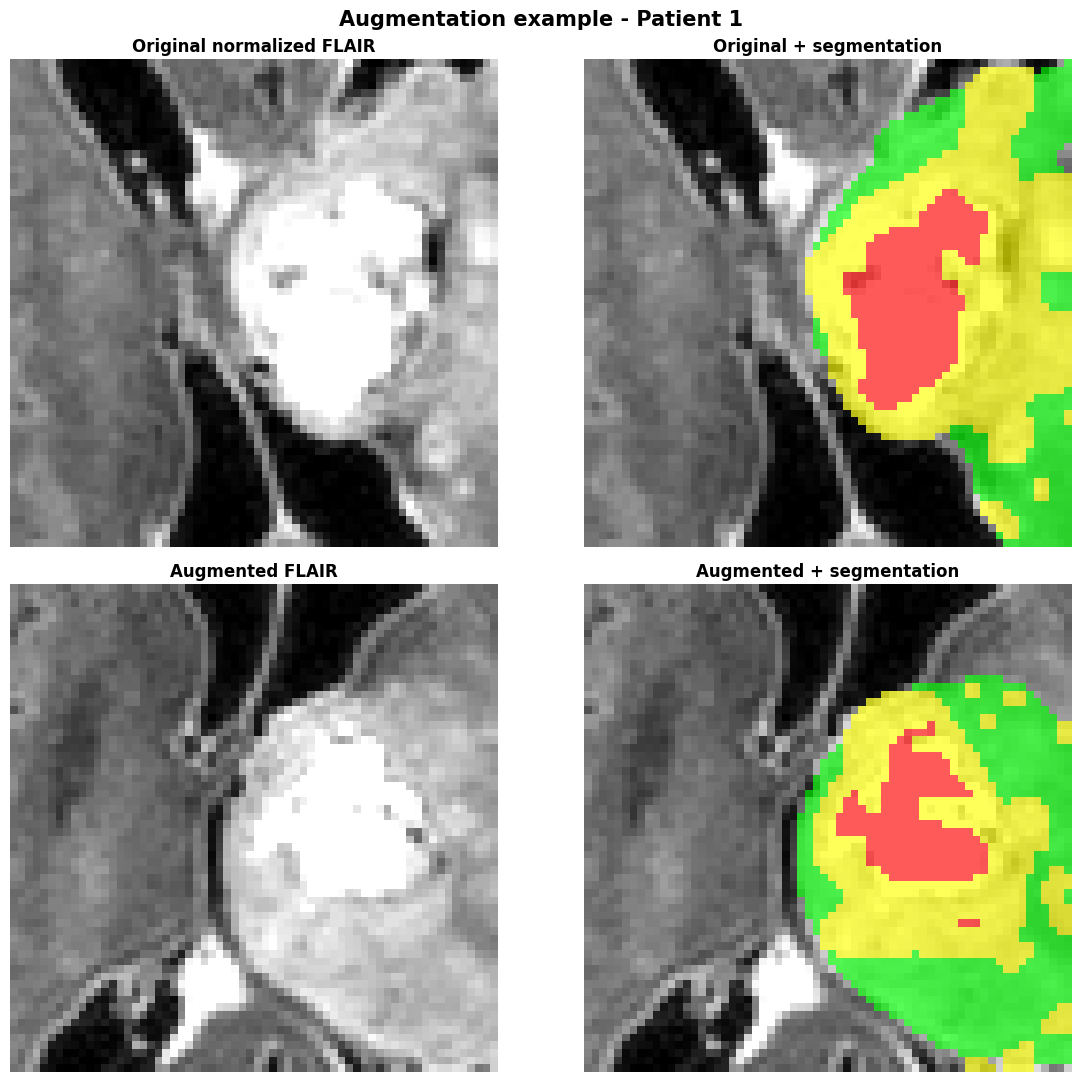

Patient: 1
Displayed axial slice: 34

Original mask labels: [0 1 2 3]
Augmented mask labels: [0 1 2 3]


In [19]:
# ================================================================
# CELL 17 - VISUALIZE PREPROCESSING AND AUGMENTATION
# ================================================================

def visualize_augmentation(
    dataframe,
    patient_index=0,
    slice_index=None
):
    """
    Visualize the effect of preprocessing and augmentation.

    Shows:
        1. Original normalized FLAIR
        2. Original segmentation
        3. Augmented FLAIR
        4. Augmented segmentation
    """

    row = dataframe.iloc[patient_index]

    # ------------------------------------------------------------
    # Load full patient volume
    # ------------------------------------------------------------

    image, mask, _ = load_patient_volumes(row)

    # ------------------------------------------------------------
    # Extract one patch
    # ------------------------------------------------------------

    original_image, original_mask = extract_3d_patch(
        image,
        mask,
        PATCH_SIZE,
        tumor_probability=1.0
    )

    # Make a copy before augmentation
    augmented_image = original_image.copy()
    augmented_mask = original_mask.copy()

    # ------------------------------------------------------------
    # Apply augmentation
    # ------------------------------------------------------------

    augmented_image, augmented_mask = augment_patch(
        augmented_image,
        augmented_mask
    )

    # ------------------------------------------------------------
    # Select slice
    # ------------------------------------------------------------

    if slice_index is None:

        # Prefer a slice containing tumor
        tumor_slices = np.where(
            original_mask.sum(axis=(0, 1)) > 0
        )[0]

        if len(tumor_slices) > 0:
            slice_index = int(
                tumor_slices[len(tumor_slices) // 2]
            )
        else:
            slice_index = PATCH_SIZE[2] // 2

    # ------------------------------------------------------------
    # Extract FLAIR slices
    # ------------------------------------------------------------

    original_flair = np.rot90(
        original_image[0, :, :, slice_index]
    )

    original_seg = np.rot90(
        original_mask[:, :, slice_index]
    )

    augmented_flair = np.rot90(
        augmented_image[0, :, :, slice_index]
    )

    augmented_seg = np.rot90(
        augmented_mask[:, :, slice_index]
    )

    # ------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(12, 11)
    )

    # ------------------------------------------------------------
    # Fixed segmentation colormap
    # ------------------------------------------------------------

    seg_cmap = ListedColormap([
        (0, 0, 0, 0),       # background
        (1, 0, 0, 0.65),    # necrotic
        (0, 1, 0, 0.65),    # FLAIR hyperintensity
        (1, 1, 0, 0.65)     # enhancing
    ])

    # ------------------------------------------------------------
    # Original FLAIR
    # ------------------------------------------------------------

    axes[0, 0].imshow(
        original_flair,
        cmap="gray"
    )

    axes[0, 0].set_title(
        "Original normalized FLAIR",
        fontsize=12,
        fontweight="bold"
    )

    axes[0, 0].axis("off")

    # ------------------------------------------------------------
    # Original segmentation
    # ------------------------------------------------------------

    axes[0, 1].imshow(
        original_flair,
        cmap="gray"
    )

    axes[0, 1].imshow(
        original_seg,
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest"
    )

    axes[0, 1].set_title(
        "Original + segmentation",
        fontsize=12,
        fontweight="bold"
    )

    axes[0, 1].axis("off")

    # ------------------------------------------------------------
    # Augmented FLAIR
    # ------------------------------------------------------------

    axes[1, 0].imshow(
        augmented_flair,
        cmap="gray"
    )

    axes[1, 0].set_title(
        "Augmented FLAIR",
        fontsize=12,
        fontweight="bold"
    )

    axes[1, 0].axis("off")

    # ------------------------------------------------------------
    # Augmented segmentation
    # ------------------------------------------------------------

    axes[1, 1].imshow(
        augmented_flair,
        cmap="gray"
    )

    axes[1, 1].imshow(
        augmented_seg,
        cmap=seg_cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest"
    )

    axes[1, 1].set_title(
        "Augmented + segmentation",
        fontsize=12,
        fontweight="bold"
    )

    axes[1, 1].axis("off")

    # ------------------------------------------------------------
    # Figure title
    # ------------------------------------------------------------

    plt.suptitle(
        f"Augmentation example - Patient {row['patient_folder']}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()

    plt.show()

    # ------------------------------------------------------------
    # Print information
    # ------------------------------------------------------------

    print(f"Patient: {row['patient_folder']}")
    print(f"Displayed axial slice: {slice_index}")

    print("\nOriginal mask labels:",
          np.unique(original_mask))

    print("Augmented mask labels:",
          np.unique(augmented_mask))


# ---------------------------------------------------------------
# Run visualization
# ---------------------------------------------------------------

visualize_augmentation(
    development_df,
    patient_index=0
)

## 3. Model: MONAI 3D U-Net

In [20]:
# ================================================================
# CELL 19 - MONAI 3D U-NET (same architecture as the baseline notebook)
# ================================================================
#
# monai.networks.nets.UNet, channels 16-32-64-128, strides 2-2-2:
#   - encoder: one residual unit per level (2 convolutions + instance norm + PReLU);
#     its first convolution has stride 2 and halves the resolution;
#   - bottom: residual unit at 128 channels;
#   - decoder: transposed convolution (x2), concatenation with the skip features,
#     residual unit; the last level outputs NUM_CLASSES logits per voxel.
# The wrapper keeps the attribute name "network", as in the baseline and MAE
# notebooks, so their checkpoints / pre-trained weights load directly.

class GliomaMONAIUNet(nn.Module):

    def __init__(
        self,
        in_channels=4,
        out_channels=4,
        base_channels=16
    ):
        super().__init__()

        self.network = UNet(
            spatial_dims=3,
            in_channels=in_channels,
            out_channels=out_channels,
            channels=(
                base_channels,
                base_channels * 2,
                base_channels * 4,
                base_channels * 8
            ),
            strides=UNET_STRIDES,
            num_res_units=NUM_RES_UNITS,
            norm="INSTANCE"
        )

    def forward(self, x):
        return self.network(x)


def build_model():
    """Fresh 3D U-Net with the configuration above."""

    return GliomaMONAIUNet(
        in_channels=NUM_INPUT_CHANNELS,
        out_channels=NUM_CLASSES,
        base_channels=BASE_CHANNELS
    )


print("3D U-Net builder defined successfully.")

# ================================================================
# CELL 20 - MODEL INITIALIZATION AND SHAPE TEST
# ================================================================

model = build_model()

# nn.DataParallel only if USE_DATA_PARALLEL = True
if use_multi_gpu():
    model = nn.DataParallel(model)

model = model.to(DEVICE)

num_parameters = sum(p.numel() for p in model.parameters())
num_trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Total parameters:", f"{num_parameters:,}")
print("Trainable parameters:", f"{num_trainable_parameters:,}")

# ---------------------------------------------------------------
# Forward-pass smoke test (training patch)
# ---------------------------------------------------------------
with torch.no_grad():

    dummy_input = torch.randn(1, NUM_INPUT_CHANNELS, *PATCH_SIZE, device=DEVICE)
    dummy_output = model(dummy_input)

print("\nInput shape :", tuple(dummy_input.shape))
print("Output shape:", tuple(dummy_output.shape))

assert dummy_output.shape == (1, NUM_CLASSES, *PATCH_SIZE)
assert torch.isfinite(dummy_output).all()

print("\n3D U-Net forward pass: OK")

del model, dummy_input, dummy_output
release_cpu_memory()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


3D U-Net builder defined successfully.
Total parameters: 1,191,413
Trainable parameters: 1,191,413

Input shape : (1, 4, 64, 64, 64)
Output shape: (1, 4, 64, 64, 64)

3D U-Net forward pass: OK


## 4. Loss and metrics (identical to the Swin UNETR)

In [21]:
# ================================================================
# CELL 21 - LOSS FUNCTIONS
# ================================================================

class SoftDiceLoss(nn.Module):
    """
    Multi-class soft Dice loss.
    
    Background class (0) is excluded from the Dice calculation.
    """

    def __init__(self, smooth=1e-5):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        """
        logits:
            [B, C, D, H, W]

        targets:
            [B, D, H, W]
        """

        num_classes = logits.shape[1]

        # Convert logits to probabilities
        probs = torch.softmax(logits, dim=1)

        # One-hot encode target
        targets_one_hot = F.one_hot(
            targets.long(),
            num_classes=num_classes
        )

        # [B, D, H, W, C] -> [B, C, D, H, W]
        targets_one_hot = targets_one_hot.permute(
            0, 4, 1, 2, 3
        ).float()

        # Exclude background
        probs = probs[:, 1:]
        targets_one_hot = targets_one_hot[:, 1:]

        # Flatten spatial dimensions
        probs = probs.reshape(
            probs.shape[0],
            probs.shape[1],
            -1
        )

        targets_one_hot = targets_one_hot.reshape(
            targets_one_hot.shape[0],
            targets_one_hot.shape[1],
            -1
        )

        # Dice per class and patient
        intersection = (
            probs * targets_one_hot
        ).sum(dim=2)

        denominator = (
            probs.sum(dim=2)
            + targets_one_hot.sum(dim=2)
        )

        dice = (
            2.0 * intersection + self.smooth
        ) / (
            denominator + self.smooth
        )

        # Mean across foreground classes and batch
        dice_loss = 1.0 - dice.mean()

        return dice_loss


class CombinedLoss(nn.Module):
    """
    Combined segmentation loss:

        0.5 * Cross Entropy
        +
        0.5 * Soft Dice
    """

    def __init__(
        self,
        ce_weight=0.5,
        dice_weight=0.5
    ):
        super().__init__()

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

        self.ce = nn.CrossEntropyLoss()
        self.dice = SoftDiceLoss()

    def forward(self, logits, targets):

        ce_loss = self.ce(logits, targets)
        dice_loss = self.dice(logits, targets)

        total_loss = (
            self.ce_weight * ce_loss
            +
            self.dice_weight * dice_loss
        )

        return total_loss, ce_loss, dice_loss


criterion = CombinedLoss(
    ce_weight=0.5,
    dice_weight=0.5
)

print("Loss functions defined successfully.")

# ================================================================
# CELL 23 - DICE AND IoU METRICS
# ================================================================

def dice_score_per_class(
    prediction,
    target,
    num_classes=NUM_CLASSES,
    include_background=False
):
    """
    Computes Dice score for each class.

    prediction:
        [B, D, H, W]

    target:
        [B, D, H, W]
    """

    scores = []

    start_class = 0 if include_background else 1

    for class_id in range(start_class, num_classes):

        pred_class = (prediction == class_id)
        target_class = (target == class_id)

        intersection = (
            pred_class & target_class
        ).sum().float()

        pred_volume = pred_class.sum().float()
        target_volume = target_class.sum().float()

        denominator = pred_volume + target_volume

        if denominator == 0:
            # Both prediction and target are empty
            dice = torch.tensor(
                1.0,
                device=prediction.device
            )
        else:
            dice = (
                2.0 * intersection
                / denominator
            )

        scores.append(dice.item())

    return scores


def iou_score_per_class(
    prediction,
    target,
    num_classes=NUM_CLASSES,
    include_background=False
):
    """
    Computes IoU score for each class.
    """

    scores = []

    start_class = 0 if include_background else 1

    for class_id in range(start_class, num_classes):

        pred_class = (prediction == class_id)
        target_class = (target == class_id)

        intersection = (
            pred_class & target_class
        ).sum().float()

        union = (
            pred_class | target_class
        ).sum().float()

        if union == 0:
            iou = torch.tensor(
                1.0,
                device=prediction.device
            )
        else:
            iou = intersection / union

        scores.append(iou.item())

    return scores


print("Dice and IoU metric functions defined successfully.")

Loss functions defined successfully.
Dice and IoU metric functions defined successfully.


## 5. Training

Same training loop as the Swin UNETR notebook: data from the cache, `last` checkpoint and
history saved after every epoch, automatic resume, clean stop before the session time limit
and before the RAM is full.

The model is trained on **one GPU** (`nn.DataParallel` made the RAM grow until the kernel
died). Validation runs on **two GPUs without `nn.DataParallel`** (`VALIDATION_GPUS = 2`): the two
volumes of each batch are predicted in parallel, one per GPU, with the same weights, so loss
and metrics do not change.

Recipe: `LR_SCHEDULE` / `GRAD_CLIP_NORM` (see the configuration cell).


In [22]:
# ================================================================
# CELL 25 - TRAINING UTILITIES
# ================================================================

from tqdm.auto import tqdm


def get_model_state_dict(model):
    """
    Returns the state_dict independently of whether
    the model is wrapped in DataParallel.
    """
    if isinstance(model, nn.DataParallel):
        return model.module.state_dict()
    return model.state_dict()


def create_model():
    """
    Creates a fresh model for each fold.
    """

    model = build_model()

    if use_multi_gpu():
        model = nn.DataParallel(model)

    model = model.to(DEVICE)

    return model


def load_model_from_checkpoint(checkpoint_path):
    """
    Loads the weights into an unwrapped model and wraps it afterwards
    (the checkpoint is saved without the 'module.' prefix of DataParallel).
    """

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    model = build_model()
    model.load_state_dict(checkpoint["model_state_dict"])

    if use_multi_gpu():
        model = nn.DataParallel(model)

    model = model.to(DEVICE)
    model.eval()

    return model, checkpoint


def create_optimizer(model):
    """
    AdamW optimizer (same settings as the Swin UNETR).
    """

    return torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )


def create_scheduler(optimizer):
    """
    LR_SCHEDULE = "constant": fixed learning rate (baseline recipe).
    LR_SCHEDULE = "warmup_cosine": linear warm-up for WARMUP_EPOCHS, then cosine decay
    to zero at MAX_EPOCHS (Swin UNETR recipe). Stepped once per epoch.
    """

    def lr_lambda(completed_epochs):

        if LR_SCHEDULE == "constant":
            return 1.0

        if completed_epochs < WARMUP_EPOCHS:
            return (completed_epochs + 1) / WARMUP_EPOCHS

        progress = (completed_epochs - WARMUP_EPOCHS) / max(1, MAX_EPOCHS - WARMUP_EPOCHS)

        return 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


def pad_to_multiple(images, divisor):
    """Zero-pads [B, C, D, H, W] at the end of each spatial axis to a multiple of divisor."""

    d, h, w = images.shape[-3:]
    pad_d, pad_h, pad_w = [(divisor - size % divisor) % divisor for size in (d, h, w)]

    return F.pad(images, (0, pad_w, 0, pad_h, 0, pad_d)), (d, h, w)


def predict_logits(model, images):
    """
    Full-volume logits with the same spatial size as the input, so loss and
    metrics are computed on the full volume.

    sliding_window: PATCH_SIZE windows (overlap SW_OVERLAP) blended with Gaussian
                    weights, exactly as in the Swin UNETR notebook.
    full_volume:    one pass on the volume zero-padded to a multiple of 8
                    (155 is not), then cropped back.
    """

    if INFERENCE_MODE == "sliding_window":

        return sliding_window_inference(
            inputs=images,
            roi_size=PATCH_SIZE,
            sw_batch_size=SW_BATCH_SIZE,
            predictor=model,
            overlap=SW_OVERLAP,
            mode=SW_MODE
        )

    padded, (d, h, w) = pad_to_multiple(images, divisor=2 ** len(UNET_STRIDES))

    return model(padded)[..., :d, :h, :w]


def compute_batch_metrics(logits, targets):
    """
    Computes mean Dice and IoU across the foreground classes
    for a batch (identical to the Swin UNETR notebook).
    """

    predictions = torch.argmax(logits, dim=1)

    dice_values = dice_score_per_class(
        predictions,
        targets,
        num_classes=NUM_CLASSES,
        include_background=False
    )

    iou_values = iou_score_per_class(
        predictions,
        targets,
        num_classes=NUM_CLASSES,
        include_background=False
    )

    return (
        float(np.mean(dice_values)),
        float(np.mean(iou_values))
    )


# ================================================================
# VALIDATION ON TWO GPUs (without nn.DataParallel)
# ================================================================
# The volumes of a validation batch are predicted in parallel, one per GPU.
# nn.DataParallel is NOT used: it leaked ~1.6 MB of RAM per call because it
# copies the model and starts new threads at every forward. Here:
#   - each GPU keeps its own copy of the model, refreshed once per validation (sync);
#   - the work goes to worker threads created once for the whole session.
# Each volume goes through exactly the same sliding-window inference with the
# same weights, so the predictions do not change (rounding-level differences only).

import contextlib
from concurrent.futures import ThreadPoolExecutor


class MultiGPUSlidingWindow:

    def __init__(self, num_gpus):

        if torch.cuda.is_available():
            num_gpus = max(1, min(num_gpus, torch.cuda.device_count()))
            self.devices = [torch.device("cuda", i) for i in range(num_gpus)]
        else:
            self.devices = [torch.device("cpu")]

        self.models = [None] * len(self.devices)

        self.pool = (
            ThreadPoolExecutor(max_workers=len(self.devices), thread_name_prefix="sliding_window")
            if len(self.devices) > 1 else None
        )

    def sync(self, model):
        """Uses the current weights of `model` on every GPU (once per validation)."""

        source = model.module if isinstance(model, nn.DataParallel) else model
        source.eval()
        self.models[0] = source

        if len(self.devices) > 1:

            state = source.state_dict()

            for i, device in enumerate(self.devices[1:], start=1):

                if self.models[i] is None:
                    self.models[i] = build_model().to(device)

                self.models[i].load_state_dict(state)
                self.models[i].eval()

    def _predict_on(self, index, images):

        device = self.devices[index]

        device_context = (
            torch.cuda.device(device) if device.type == "cuda" else contextlib.nullcontext()
        )

        # Gradient and autocast settings are per thread: they are set here
        with device_context, torch.no_grad(), torch.autocast(
            device_type="cuda", enabled=device.type == "cuda"
        ):
            return predict_logits(
                self.models[index],
                images.to(device, non_blocking=True)
            ).float()

    def predict(self, images):
        """images [B, C, D, H, W] (CPU or GPU) -> float logits [B, classes, D, H, W] on DEVICE."""

        chunks = torch.tensor_split(images, min(len(self.devices), images.shape[0]))

        if self.pool is None or len(chunks) == 1:
            outputs = [self._predict_on(0, images)]
        else:
            futures = [
                self.pool.submit(self._predict_on, i, chunk)
                for i, chunk in enumerate(chunks)
            ]
            outputs = [future.result() for future in futures]

        return torch.cat([output.to(DEVICE) for output in outputs], dim=0)


VALIDATION_PREDICTOR = MultiGPUSlidingWindow(VALIDATION_GPUS)

print("GPUs used for validation and evaluation:", len(VALIDATION_PREDICTOR.devices))
print("Training utilities defined successfully.")

# ================================================================
# CELL 26 - TRAIN ONE EPOCH
# ================================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler
):
    model.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice_loss = 0.0

    running_dice = 0.0
    running_iou = 0.0

    num_batches = 0

    progress_bar = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for batch in progress_bar:

        images = batch["image"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["mask"].to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # --------------------------------------------------------
        # Mixed precision forward pass
        # --------------------------------------------------------
        with torch.cuda.amp.autocast(
            enabled=torch.cuda.is_available()
        ):

            logits = model(images)

            total_loss, ce_loss, dice_loss = criterion(
                logits,
                masks
            )

        # --------------------------------------------------------
        # Backpropagation (+ optional gradient clipping, GRAD_CLIP_NORM)
        # --------------------------------------------------------
        scaler.scale(total_loss).backward()

        if GRAD_CLIP_NORM is not None:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP_NORM
            )

        scaler.step(optimizer)
        scaler.update()

        # --------------------------------------------------------
        # Metrics
        # --------------------------------------------------------
        batch_dice, batch_iou = compute_batch_metrics(
            logits.detach(),
            masks
        )

        running_loss += total_loss.item()
        running_ce += ce_loss.item()
        running_dice_loss += dice_loss.item()

        running_dice += batch_dice
        running_iou += batch_iou

        num_batches += 1

        progress_bar.set_postfix(
            loss=f"{total_loss.item():.4f}",
            dice=f"{batch_dice:.4f}"
        )

        # Memory management only (no effect on the training)
        if num_batches % TRIM_EVERY_TRAIN_BATCHES == 0:
            release_cpu_memory()

        if MEMORY_EMERGENCY.is_set():
            raise MemoryError("RAM almost full during training.")

    return {
        "loss": running_loss / num_batches,
        "ce_loss": running_ce / num_batches,
        "dice_loss": running_dice_loss / num_batches,
        "dice": running_dice / num_batches,
        "iou": running_iou / num_batches
    }

# ================================================================
# CELL 27 - VALIDATION (full volumes, sliding-window inference)
# ================================================================

def validate_one_epoch(
    model,
    loader,
    criterion
):
    model.eval()

    # Current weights on every validation GPU (one copy per epoch)
    VALIDATION_PREDICTOR.sync(model)

    running_loss = 0.0
    running_ce = 0.0
    running_dice_loss = 0.0

    running_dice = 0.0
    running_iou = 0.0

    num_batches = 0

    with torch.no_grad():

        progress_bar = tqdm(
            loader,
            desc="Validation",
            leave=False
        )

        for batch in progress_bar:

            # Each volume is moved to its own GPU by the predictor
            images = batch["image"]

            masks = batch["mask"].to(
                DEVICE,
                non_blocking=True
            )

            with torch.cuda.amp.autocast(
                enabled=torch.cuda.is_available()
            ):

                # Same sliding-window logits as predict_logits(model, images),
                # computed with one volume per GPU
                logits = VALIDATION_PREDICTOR.predict(images)

                total_loss, ce_loss, dice_loss = criterion(
                    logits,
                    masks
                )

            batch_dice, batch_iou = compute_batch_metrics(
                logits,
                masks
            )

            running_loss += total_loss.item()
            running_ce += ce_loss.item()
            running_dice_loss += dice_loss.item()

            running_dice += batch_dice
            running_iou += batch_iou

            num_batches += 1

            progress_bar.set_postfix(
                loss=f"{total_loss.item():.4f}",
                dice=f"{batch_dice:.4f}"
            )

            # Memory management only (no effect on the metrics)
            del images, masks, logits

            if num_batches % TRIM_EVERY_VAL_BATCHES == 0:
                release_cpu_memory()

            if MEMORY_EMERGENCY.is_set():
                raise MemoryError("RAM almost full during validation.")

    return {
        "loss": running_loss / num_batches,
        "ce_loss": running_ce / num_batches,
        "dice_loss": running_dice_loss / num_batches,
        "dice": running_dice / num_batches,
        "iou": running_iou / num_batches
    }


print("Training and validation functions defined successfully.")


GPUs used for validation and evaluation: 2
Training utilities defined successfully.
Training and validation functions defined successfully.


In [ ]:
# ================================================================
# CELL 28 - CROSS-VALIDATION TRAINING (resumable)
# ================================================================

set_seed(SEED)

all_fold_results = []
all_fold_histories = []

fold_completed = {}
SESSION_STOPPED = False


def hours_used():
    return (time.time() - NOTEBOOK_START_TIME) / 3600


# ---------------------------------------------------------------
# Memory monitor: a "Kernel died" without a Python error is almost
# always the system running out of RAM. This logs RAM and shared
# memory every MEMORY_LOG_SECONDS and prints a warning above 85%.
# ---------------------------------------------------------------
import threading

try:
    import psutil
except ImportError:
    psutil = None


def memory_snapshot():
    """
    System RAM + private memory (USS, shared pages counted once) of the
    notebook process and of its DataLoader workers.
    """

    if psutil is None:
        return {}

    vm = psutil.virtual_memory()
    main_process = psutil.Process()

    try:
        main_gb = main_process.memory_full_info().uss / 1e9
    except psutil.Error:
        main_gb = main_process.memory_info().rss / 1e9

    workers_gb = 0.0

    for child in main_process.children(recursive=True):
        try:
            workers_gb += child.memory_full_info().uss / 1e9
        except psutil.Error:
            pass

    shm = shutil.disk_usage("/dev/shm") if Path("/dev/shm").exists() else None

    return {
        "ram_used_gb": vm.used / 1e9,
        "ram_available_gb": vm.available / 1e9,
        "ram_total_gb": vm.total / 1e9,
        "ram_percent": vm.percent,
        "notebook_process_gb": main_gb,
        "workers_gb": workers_gb,
        "threads": main_process.num_threads(),
        "shm_used_gb": shm.used / 1e9 if shm else float("nan"),
        "shm_total_gb": shm.total / 1e9 if shm else float("nan")
    }


def memory_summary():

    s = memory_snapshot()

    if not s:
        return "memory: psutil not available"

    return (
        f"RAM {s['ram_used_gb']:.1f}/{s['ram_total_gb']:.1f} GB ({s['ram_percent']:.0f}%) "
        f"| notebook process {s['notebook_process_gb']:.1f} GB "
        f"| workers {s['workers_gb']:.1f} GB "
        f"| threads {s['threads']} "
        f"| /dev/shm {s['shm_used_gb']:.1f}/{s['shm_total_gb']:.1f} GB"
    )


class MemoryMonitor(threading.Thread):

    def __init__(self, path, interval):
        super().__init__(daemon=True)
        self.path = path
        self.interval = interval
        self.stop_event = threading.Event()

    def run(self):

        while not self.stop_event.wait(self.interval):

            snapshot = memory_snapshot()

            if not snapshot:
                return

            snapshot["hours"] = hours_used()

            pd.DataFrame([snapshot]).to_csv(
                self.path,
                mode="a",
                header=not self.path.exists(),
                index=False
            )

            if snapshot["ram_percent"] > EMERGENCY_RAM_PERCENT:
                MEMORY_EMERGENCY.set()

            if snapshot["ram_percent"] > 80:
                print(f"\n⚠ HIGH MEMORY USAGE: {memory_summary()}", flush=True)

    def stop(self):
        self.stop_event.set()


# One memory log per session (a resumed session also copies the previous logs)
MEMORY_LOG_PATH = RESULTS_DIR / f"memory_log_{time.strftime('%Y%m%d_%H%M')}.csv"

MEMORY_EMERGENCY.clear()
memory_monitor = MemoryMonitor(MEMORY_LOG_PATH, MEMORY_LOG_SECONDS)
memory_monitor.start()

print("Memory before training:", memory_summary())


def unwrap_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def capture_rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
    }


def restore_rng_state(state):

    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])

    if (
        state["cuda"] is not None
        and torch.cuda.is_available()
        and len(state["cuda"]) == torch.cuda.device_count()
    ):
        torch.cuda.set_rng_state_all(state["cuda"])


# ===============================================================
# LOOP OVER THE FOLDS
# ===============================================================

for fold in FOLDS_TO_RUN:

    print("\n")
    print("=" * 70)
    print(f"STARTING FOLD {fold}")
    print("=" * 70)

    train_fold_df, val_fold_df = get_fold_split(fold)

    print(f"Training patients   : {len(train_fold_df)}")
    print(f"Validation patients : {len(val_fold_df)}")

    best_path = CHECKPOINT_DIR / f"unet3d_fold{fold}_best.pth"
    last_path = CHECKPOINT_DIR / f"unet3d_fold{fold}_last.pth"

    # -----------------------------------------------------------
    # Fresh model, optimizer, scheduler, loss, scaler
    # -----------------------------------------------------------
    model = create_model()
    optimizer = create_optimizer(model)
    scheduler = create_scheduler(optimizer)

    criterion = CombinedLoss(
        ce_weight=0.5,
        dice_weight=0.5
    )

    scaler = torch.cuda.amp.GradScaler(
        enabled=torch.cuda.is_available()
    )

    history = []

    best_val_loss = float("inf")
    best_val_dice = -float("inf")

    epochs_without_improvement = 0
    best_epoch = 0
    start_epoch = 1
    finished = False

    # -----------------------------------------------------------
    # Resume from the last checkpoint of this fold, if present
    # -----------------------------------------------------------
    if last_path.exists():

        state = torch.load(last_path, map_location="cpu", weights_only=False)

        unwrap_model(model).load_state_dict(state["model_state_dict"])
        optimizer.load_state_dict(state["optimizer_state_dict"])
        scheduler.load_state_dict(state["scheduler_state_dict"])
        scaler.load_state_dict(state["scaler_state_dict"])

        history = state["history"]
        best_val_loss = state["best_val_loss"]
        best_val_dice = state["best_val_dice"]
        best_epoch = state["best_epoch"]
        epochs_without_improvement = state["epochs_without_improvement"]
        start_epoch = state["epoch"] + 1
        finished = state["finished"]

        restore_rng_state(state["rng_state"])

        print(
            f"Resumed from epoch {state['epoch']} "
            f"(best epoch {best_epoch}, best val loss {best_val_loss:.4f})"
        )

        if finished:
            print("Training of this fold was already completed: skipping to the results.")

    train_loader = None
    val_loader = None
    stopped_for_time = False
    stopped_for_memory = False

    if not finished:

        train_dataset = CachedGlioma3DDataset(train_fold_df, training=True)
        val_dataset = CachedGlioma3DDataset(val_fold_df, training=False)

        # Workers are NOT persistent: they are recreated at every epoch,
        # so any memory they accumulate is released.
        train_loader = DataLoader(
            train_dataset,
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=NUM_WORKERS,
            pin_memory=torch.cuda.is_available(),
            persistent_workers=False
        )

        # Validation batches are full volumes (~0.3 GB each):
        # fewer workers, no prefetch queue, no pinned-memory copies.
        val_loader_kwargs = dict(
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=VAL_NUM_WORKERS,
            pin_memory=False,
            persistent_workers=False
        )

        if VAL_NUM_WORKERS > 0:
            val_loader_kwargs["prefetch_factor"] = 1

        val_loader = DataLoader(val_dataset, **val_loader_kwargs)

        print(f"Training patches per epoch   : {len(train_dataset)}")
        print(f"Validation samples per epoch : {len(val_dataset)}")

    # RAM growth of the last epoch (for the memory budget)
    previous_ram_gb = memory_snapshot().get("ram_used_gb")
    epoch_ram_growth_gb = None

    # ===========================================================
    # EPOCH LOOP
    # ===========================================================

    for epoch in range(start_epoch, MAX_EPOCHS + 1):

        if finished:
            break

        # -------------------------------------------------------
        # Session time budget: do not start an epoch that would
        # not finish before MAX_SESSION_HOURS
        # -------------------------------------------------------
        recent_epoch_hours = (
            np.mean([h["epoch_time_seconds"] for h in history[-5:]]) / 3600
            if history else 0.0
        )

        if hours_used() + 1.15 * recent_epoch_hours > MAX_SESSION_HOURS:

            stopped_for_time = True

            print(
                f"\n⏸ SESSION TIME BUDGET REACHED ({hours_used():.2f} h used): "
                f"training of fold {fold} stops after epoch {epoch - 1}. "
                "Resume it in the next session with RESUME_FROM."
            )

            break

        # -------------------------------------------------------
        # Memory budget: do not start an epoch that would fill the RAM
        # -------------------------------------------------------
        if epoch_ram_growth_gb is not None and psutil is not None:

            vm = psutil.virtual_memory()

            predicted_percent = 100 * (
                vm.total - vm.available + 1.2 * max(epoch_ram_growth_gb, 0.0) * 1e9
            ) / vm.total

            if predicted_percent > MAX_RAM_PERCENT:

                stopped_for_memory = True

                print(
                    f"\n⏸ MEMORY BUDGET REACHED: RAM {vm.percent:.0f}% and "
                    f"+{epoch_ram_growth_gb:.1f} GB in the last epoch. Training of fold {fold} "
                    f"stops after epoch {epoch - 1}. Resume it in the next session with RESUME_FROM."
                )

                break

        epoch_start_time = time.time()

        current_lr = optimizer.param_groups[0]["lr"]

        print("\n")
        print("-" * 70)
        print(f"Fold {fold} | Epoch {epoch}/{MAX_EPOCHS} | LR {current_lr:.2e}")
        print("-" * 70)

        # -------------------------------------------------------
        # Training and validation (same functions as before)
        # -------------------------------------------------------
        try:

            train_metrics = train_one_epoch(
                model,
                train_loader,
                optimizer,
                criterion,
                scaler
            )

            release_cpu_memory()
            ram_after_train_gb = memory_snapshot().get("ram_used_gb", float("nan"))

            val_metrics = validate_one_epoch(
                model,
                val_loader,
                criterion
            )

        except MemoryError as error:

            # The epoch is discarded: last checkpoint = previous epoch
            stopped_for_memory = True
            release_cpu_memory()

            print(
                f"\n⛔ {error} Epoch {epoch} interrupted; training of fold {fold} resumes "
                f"from epoch {epoch} in the next session (RESUME_FROM)."
            )

            break

        scheduler.step()

        # Release memory held by the validation volumes before the next epoch
        release_cpu_memory()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        epoch_time = time.time() - epoch_start_time

        memory_now = memory_snapshot()

        if previous_ram_gb is not None and "ram_used_gb" in memory_now:
            epoch_ram_growth_gb = memory_now["ram_used_gb"] - previous_ram_gb
            previous_ram_gb = memory_now["ram_used_gb"]

        epoch_result = {
            "fold": fold,
            "epoch": epoch,
            "learning_rate": current_lr,

            "train_loss": train_metrics["loss"],
            "train_ce_loss": train_metrics["ce_loss"],
            "train_dice_loss": train_metrics["dice_loss"],
            "train_dice": train_metrics["dice"],
            "train_iou": train_metrics["iou"],

            "val_loss": val_metrics["loss"],
            "val_ce_loss": val_metrics["ce_loss"],
            "val_dice_loss": val_metrics["dice_loss"],
            "val_dice": val_metrics["dice"],
            "val_iou": val_metrics["iou"],

            "epoch_time_seconds": epoch_time,

            "ram_percent": memory_now.get("ram_percent", float("nan")),
            "ram_used_gb": memory_now.get("ram_used_gb", float("nan")),
            "ram_after_train_gb": ram_after_train_gb,
            "notebook_process_gb": memory_now.get("notebook_process_gb", float("nan")),
            "shm_used_gb": memory_now.get("shm_used_gb", float("nan")),
            "data_parallel": use_multi_gpu()
        }

        history.append(epoch_result)

        pd.DataFrame(history).to_csv(
            RESULTS_DIR / f"fold_{fold}_history.csv",
            index=False
        )

        # -------------------------------------------------------
        # Epoch summary and progress
        # -------------------------------------------------------
        print(
            f"\nTrain loss: {train_metrics['loss']:.4f}"
            f" | Train Dice: {train_metrics['dice']:.4f}"
            f" | Train IoU: {train_metrics['iou']:.4f}"
        )

        print(
            f"Val loss:   {val_metrics['loss']:.4f}"
            f" | Val Dice:   {val_metrics['dice']:.4f}"
            f" | Val IoU:    {val_metrics['iou']:.4f}"
        )

        mean_epoch_minutes = np.mean([h["epoch_time_seconds"] for h in history]) / 60
        remaining_epochs = MAX_EPOCHS - epoch

        print(
            f"Epoch time: {epoch_time / 60:.2f} min "
            f"| mean {mean_epoch_minutes:.1f} min/epoch "
            f"| at most {remaining_epochs * mean_epoch_minutes / 60:.1f} h left for this fold "
            f"(less with early stopping) "
            f"| session time used {hours_used():.2f}/{MAX_SESSION_HOURS} h"
        )

        print("Memory:", memory_summary())

        if epoch_ram_growth_gb is not None:
            print(f"RAM change in this epoch: {epoch_ram_growth_gb:+.1f} GB")

        # -------------------------------------------------------
        # Best checkpoint (same criterion as the baseline: val loss)
        # -------------------------------------------------------
        if val_metrics["loss"] < best_val_loss:

            best_val_loss = val_metrics["loss"]
            best_val_dice = val_metrics["dice"]
            best_epoch = epoch

            epochs_without_improvement = 0

            torch.save({
                "fold": fold,
                "epoch": epoch,
                "model_state_dict": get_model_state_dict(model),
                "best_val_loss": best_val_loss,
                "best_val_dice": best_val_dice,
                "config": {
                    "architecture": MODEL_NAME,
                    "patch_size": PATCH_SIZE,
                    "batch_size": BATCH_SIZE,
                    "base_channels": BASE_CHANNELS,
                    "num_res_units": NUM_RES_UNITS,
                    "strides": UNET_STRIDES,
                    "learning_rate": LEARNING_RATE,
                    "weight_decay": WEIGHT_DECAY,
                    "lr_schedule": LR_SCHEDULE,
                    "warmup_epochs": WARMUP_EPOCHS,
                    "grad_clip_norm": GRAD_CLIP_NORM,
                    "inference_mode": INFERENCE_MODE,
                    "num_classes": NUM_CLASSES,
                    "num_input_channels": NUM_INPUT_CHANNELS
                }
            }, best_path)

            print(f"✓ Best checkpoint saved: {best_path.name}")

        else:

            epochs_without_improvement += 1

            print(f"No improvement for {epochs_without_improvement} epoch(s).")

        # -------------------------------------------------------
        # Early stopping / end of training
        # -------------------------------------------------------
        if epochs_without_improvement >= PATIENCE:

            print(f"\nEarly stopping triggered after {PATIENCE} epochs without improvement.")
            finished = True

        if epoch == MAX_EPOCHS:
            finished = True

        # -------------------------------------------------------
        # Last checkpoint: everything needed to resume
        # -------------------------------------------------------
        torch.save({
            "epoch": epoch,
            "finished": finished,
            "model_state_dict": get_model_state_dict(model),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "history": history,
            "best_val_loss": best_val_loss,
            "best_val_dice": best_val_dice,
            "best_epoch": best_epoch,
            "epochs_without_improvement": epochs_without_improvement,
            "rng_state": capture_rng_state()
        }, last_path)

    # ===========================================================
    # END OF FOLD
    # ===========================================================

    fold_completed[fold] = finished

    if history:

        history_df = pd.DataFrame(history)

        history_df.to_csv(
            RESULTS_DIR / f"fold_{fold}_history.csv",
            index=False
        )

        best_row = history_df.loc[history_df["val_loss"].idxmin()]

        fold_result = {
            "fold": fold,
            "completed": finished,
            "epochs_trained": len(history_df),
            "best_epoch": int(best_row["epoch"]),
            "best_val_loss": float(best_row["val_loss"]),
            "best_val_dice": float(best_row["val_dice"]),
            "best_val_iou": float(best_row["val_iou"]),
            "training_time_minutes": float(history_df["epoch_time_seconds"].sum() / 60.0),
            "mean_epoch_minutes": float(history_df["epoch_time_seconds"].mean() / 60.0),
            "num_parameters": int(sum(p.numel() for p in model.parameters()))
        }

        all_fold_results.append(fold_result)
        all_fold_histories.append(history_df)

        print("\n")
        print("=" * 70)
        print(f"FOLD {fold} {'COMPLETED' if finished else 'PAUSED'}")
        print("=" * 70)

        print(f"Epochs trained : {fold_result['epochs_trained']}")
        print(f"Best epoch     : {fold_result['best_epoch']}")
        print(f"Best val loss  : {fold_result['best_val_loss']:.4f}")
        print(f"Best val Dice  : {fold_result['best_val_dice']:.4f}")
        print(f"Best val IoU   : {fold_result['best_val_iou']:.4f}")
        print(f"Training time  : {fold_result['training_time_minutes']:.2f} min")

    # -----------------------------------------------------------
    # Free memory before next fold
    # -----------------------------------------------------------
    model = optimizer = scheduler = scaler = None
    train_loader = val_loader = None

    release_cpu_memory()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    if stopped_for_time or stopped_for_memory:
        SESSION_STOPPED = True
        break


# ===============================================================
# SAVE CV SUMMARY
# ===============================================================

fold_results_df = pd.DataFrame(all_fold_results)

fold_results_path = RESULTS_DIR / "5fold_summary.csv"

fold_results_df.to_csv(fold_results_path, index=False)

print("\n")
print("=" * 70)
print("TRAINING SESSION FINISHED" if not SESSION_STOPPED else "TRAINING SESSION PAUSED")
print("=" * 70)

if len(fold_results_df):

    display(fold_results_df)

    completed_df = fold_results_df[fold_results_df["completed"]]

    if len(completed_df):
        print("\nMean validation Dice (completed folds):", completed_df["best_val_dice"].mean())
        print("Std validation Dice (completed folds):", completed_df["best_val_dice"].std())
        print("\nMean validation IoU (completed folds):", completed_df["best_val_iou"].mean())
        print("Std validation IoU (completed folds):", completed_df["best_val_iou"].std())

if SESSION_STOPPED:
    print(
        "\nTo continue: Save Version, then in a new session add this version's output as "
        f"input and set RESUME_FROM to its {OUTPUT_DIR.name} folder."
    )

memory_monitor.stop()

print("\nResults saved to:", fold_results_path)
print(f"Session time used: {hours_used():.2f} h")
print("Memory at the end of training:", memory_summary())


Memory before training: RAM 3.4/33.7 GB (12%) | notebook process 2.2 GB | workers 0.0 GB | threads 23 | /dev/shm 0.0/15.0 GB


STARTING FOLD 1
Training patients   : 802
Validation patients : 201
Training patches per epoch   : 1604
Validation samples per epoch : 201


----------------------------------------------------------------------
Fold 1 | Epoch 1/50 | LR 1.00e-04
----------------------------------------------------------------------


Training:   0%|          | 0/802 [00:00<?, ?it/s]

Validation:   0%|          | 0/101 [00:00<?, ?it/s]


Train loss: 0.6849 | Train Dice: 0.4231 | Train IoU: 0.3159
Val loss:   0.5464 | Val Dice:   0.4128 | Val IoU:    0.2854
Epoch time: 2.97 min | mean 3.0 min/epoch | at most 2.4 h left for this fold (less with early stopping) | session time used 0.37/10.5 h
Memory: RAM 4.3/33.7 GB (17%) | notebook process 3.1 GB | workers 0.0 GB | threads 29 | /dev/shm 0.4/15.0 GB
RAM change in this epoch: +1.2 GB
✓ Best checkpoint saved: unet3d_fold1_best.pth


----------------------------------------------------------------------
Fold 1 | Epoch 2/50 | LR 1.00e-04
----------------------------------------------------------------------


Training:   0%|          | 0/802 [00:00<?, ?it/s]

Validation:   0%|          | 0/101 [00:00<?, ?it/s]

... (113 outputs left out)

Validation:   0%|          | 0/101 [00:00<?, ?it/s]


Train loss: 0.2485 | Train Dice: 0.8130 | Train IoU: 0.7283
Val loss:   0.1510 | Val Dice:   0.8024 | Val IoU:    0.6962
Epoch time: 2.70 min | mean 2.6 min/epoch | at most 0.4 h left for this fold (less with early stopping) | session time used 2.06/10.5 h
Memory: RAM 4.2/33.7 GB (16%) | notebook process 2.7 GB | workers 0.0 GB | threads 29 | /dev/shm 0.3/15.0 GB
RAM change in this epoch: -0.1 GB
No improvement for 6 epoch(s).


----------------------------------------------------------------------
Fold 1 | Epoch 41/50 | LR 1.00e-04
----------------------------------------------------------------------


Training:   0%|          | 0/802 [00:00<?, ?it/s]

Validation:   0%|          | 0/101 [00:00<?, ?it/s]

## 6. Training curves and qualitative results

In [ ]:
# ================================================================
# CELL 29 - TRAINING / VALIDATION CURVES
# ================================================================

available_folds = [
    fold for fold in range(N_FOLDS)
    if (RESULTS_DIR / f"fold_{fold}_history.csv").exists()
]

fig, axes = plt.subplots(
    3,
    2,
    figsize=(16, 15)
)

for fold in available_folds:

    history = pd.read_csv(
        RESULTS_DIR / f"fold_{fold}_history.csv"
    )

    for row, metric in enumerate(["loss", "dice", "iou"]):

        axes[row, 0].plot(
            history["epoch"],
            history[f"train_{metric}"],
            label=f"Fold {fold}",
            linewidth=2
        )

        axes[row, 1].plot(
            history["epoch"],
            history[f"val_{metric}"],
            label=f"Fold {fold}",
            linewidth=2
        )

titles = [
    ("Training Loss", "Validation Loss", "Loss"),
    ("Training Dice", "Validation Dice", "Dice"),
    ("Training IoU", "Validation IoU", "IoU")
]

for row, (left, right, ylabel) in enumerate(titles):

    axes[row, 0].set_title(left, fontsize=14, fontweight="bold")
    axes[row, 1].set_title(right, fontsize=14, fontweight="bold")

    axes[row, 0].set_ylabel(ylabel)
    axes[row, 1].set_ylabel(ylabel)

for ax in axes.flat:

    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)

plt.suptitle(
    f"{MODEL_NAME} Cross-Validation Training Curves",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

curve_path = RESULTS_DIR / "5fold_training_curves.png"

plt.savefig(curve_path, dpi=200, bbox_inches="tight")

plt.show()

print(f"Training curves saved to: {curve_path}")

# ================================================================
# CELL 30 - LOSS CURVES AND LEARNING RATE
# ================================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for fold in available_folds:

    history = pd.read_csv(
        RESULTS_DIR / f"fold_{fold}_history.csv"
    )

    axes[0].plot(
        history["epoch"],
        history["train_loss"],
        linestyle="-",
        linewidth=1.8,
        alpha=0.8,
        label=f"Fold {fold} - Train"
    )

    axes[0].plot(
        history["epoch"],
        history["val_loss"],
        linestyle="--",
        linewidth=1.8,
        alpha=0.8,
        label=f"Fold {fold} - Validation"
    )

    axes[1].plot(
        history["epoch"],
        history["learning_rate"],
        linewidth=1.8,
        label=f"Fold {fold}"
    )

axes[0].set_xlabel("Epoch", fontsize=12)
axes[0].set_ylabel("Combined Loss", fontsize=12)
axes[0].set_title(f"{MODEL_NAME} Training and Validation Loss", fontsize=15, fontweight="bold")
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=9)

axes[1].set_xlabel("Epoch", fontsize=12)
axes[1].set_ylabel("Learning rate", fontsize=12)
axes[1].set_title(f"Learning rate ({LR_SCHEDULE})", fontsize=15, fontweight="bold")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

loss_curve_path = RESULTS_DIR / "5fold_loss_curves.png"

plt.savefig(loss_curve_path, dpi=200, bbox_inches="tight")

plt.show()

print(f"Loss curves saved to: {loss_curve_path}")


In [ ]:
# ================================================================
# CELL 31 - PREDICTION VISUALIZATION
# ================================================================

SEG_CMAP = ListedColormap([
    (0, 0, 0, 0),       # background
    (1, 0, 0, 0.65),    # necrotic
    (0, 1, 0, 0.65),    # FLAIR hyperintensity
    (1, 1, 0, 0.65)     # enhancing
])


def visualize_prediction(
    model,
    dataframe,
    patient_index=0,
    slice_index=None,
    load_fn=load_patient_volumes
):
    """
    Shows FLAIR, ground truth and prediction on the axial slice
    with the largest tumor area (original image, true mask, predicted mask).
    """

    row = dataframe.iloc[patient_index]

    image, mask, _ = load_fn(row)

    images = torch.from_numpy(image).unsqueeze(0).to(DEVICE)

    model.eval()

    with torch.no_grad():
        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            logits = predict_logits(model, images).float()

    prediction = torch.argmax(logits, dim=1)[0].cpu().numpy()

    if slice_index is None:
        slice_index = int(np.argmax((mask > 0).sum(axis=(0, 1))))

    dice_values = dice_score_per_class(
        torch.from_numpy(prediction)[None],
        torch.from_numpy(mask.astype(np.int64))[None]
    )

    flair = np.rot90(image[0, :, :, slice_index])

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(flair, cmap="gray")
    axes[0].set_title("FLAIR", fontsize=12, fontweight="bold")

    axes[1].imshow(flair, cmap="gray")
    axes[1].imshow(np.rot90(mask[:, :, slice_index]), cmap=SEG_CMAP,
                   vmin=0, vmax=3, interpolation="nearest")
    axes[1].set_title("Ground truth", fontsize=12, fontweight="bold")

    axes[2].imshow(flair, cmap="gray")
    axes[2].imshow(np.rot90(prediction[:, :, slice_index]), cmap=SEG_CMAP,
                   vmin=0, vmax=3, interpolation="nearest")
    axes[2].set_title(f"{MODEL_NAME} prediction", fontsize=12, fontweight="bold")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"Patient {row['patient_folder']} | slice {slice_index} | "
        f"Dice NCR {dice_values[0]:.2f} - FLAIR {dice_values[1]:.2f} - ET {dice_values[2]:.2f}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


print("Prediction visualization function defined.")


In [ ]:
# ================================================================
# CELL 32 - LOAD BEST CHECKPOINT AND VISUALIZE
# ================================================================

FOLD_TO_VISUALIZE = FOLDS_TO_RUN[0]
N_PATIENTS_TO_SHOW = 4

best_path = CHECKPOINT_DIR / f"unet3d_fold{FOLD_TO_VISUALIZE}_best.pth"

if best_path.exists():

    visualization_model, checkpoint = load_model_from_checkpoint(best_path)

    _, fold_val_df = get_fold_split(FOLD_TO_VISUALIZE)

    print(
        f"Loaded checkpoint from fold {FOLD_TO_VISUALIZE} "
        f"(epoch {checkpoint['epoch']}, val loss {checkpoint['best_val_loss']:.4f})"
    )

    for patient_index in range(min(N_PATIENTS_TO_SHOW, len(fold_val_df))):

        visualize_prediction(
            visualization_model,
            fold_val_df,
            patient_index=patient_index,
            load_fn=load_cached_full_volume
        )

    del visualization_model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

else:
    print(f"No checkpoint yet for fold {FOLD_TO_VISUALIZE}.")


## 7. Full evaluation (Dice, IoU, HD, HD95 for whole tumor and sub-regions)

In [ ]:
# ================================================================
# CELL 33 - FULL EVALUATION: Dice, IoU, HD, HD95 PER REGION
# ================================================================
#
# Objective 1a: whole tumor (labels 1 + 2 + 3)
# Objective 1b: necrotic core (1), FLAIR hyperintensity (2), enhancing tumor (3)
#
# Conventions (BraTS):
#   region empty in prediction AND ground truth -> Dice = IoU = 1, HD = HD95 = 0
#   region empty in only one of the two          -> Dice = IoU = 0, HD = HD95 = 373.13 mm
#
# evaluate_patients() takes a generic predict_fn(images) -> logits and a
# load_fn(row) -> (image, mask, _). The same cell is used in the Swin UNETR
# notebook, so both models are evaluated in exactly the same way.

EVAL_REGIONS = {
    "Whole tumor": [1, 2, 3],
    "Necrotic core": [1],
    "FLAIR hyperintensity": [2],
    "Enhancing tumor": [3]
}

SPACING_MM = (1.0, 1.0, 1.0)
HD_MAX_MM = float(np.sqrt(240 ** 2 + 240 ** 2 + 155 ** 2))   # 373.13 mm

RUN_FULL_EVALUATION = True   # out-of-fold validation metrics (each development patient once)
EVALUATE_TEST = False        # internal test set: only for the final model comparison


def surface(binary):
    return binary ^ binary_erosion(binary, structure=np.ones((3, 3, 3)), border_value=0)


def hausdorff_distances(pred, target):
    """HD and HD95 (mm): max of the two directed surface distances."""

    if not pred.any() and not target.any():
        return 0.0, 0.0

    if not pred.any() or not target.any():
        return HD_MAX_MM, HD_MAX_MM

    # Restrict to the bounding box of both objects (same distances, faster)
    coords = np.argwhere(pred | target)
    low = np.maximum(coords.min(axis=0) - 2, 0)
    high = coords.max(axis=0) + 3
    box = tuple(slice(a, b) for a, b in zip(low, high))
    pred, target = pred[box], target[box]

    pred_surface, target_surface = surface(pred), surface(target)

    d_pred_to_target = distance_transform_edt(~target_surface, sampling=SPACING_MM)[pred_surface]
    d_target_to_pred = distance_transform_edt(~pred_surface, sampling=SPACING_MM)[target_surface]

    hd = max(d_pred_to_target.max(), d_target_to_pred.max())
    hd95 = max(np.percentile(d_pred_to_target, 95), np.percentile(d_target_to_pred, 95))

    return float(hd), float(hd95)


def region_metrics(prediction, target):

    rows = []

    for region, labels in EVAL_REGIONS.items():

        p = np.isin(prediction, labels)
        t = np.isin(target, labels)

        p_sum, t_sum = int(p.sum()), int(t.sum())
        intersection = int(np.logical_and(p, t).sum())

        if p_sum + t_sum == 0:
            dice, iou = 1.0, 1.0
        else:
            dice = 2 * intersection / (p_sum + t_sum)
            iou = intersection / (p_sum + t_sum - intersection)

        hd, hd95 = hausdorff_distances(p, t)

        rows.append({
            "region": region,
            "Dice": dice,
            "IoU": iou,
            "HD_mm": hd,
            "HD95_mm": hd95,
            "gt_empty": t_sum == 0,
            "pred_empty": p_sum == 0
        })

    return rows


def evaluate_patients(predict_fn, dataframe, description="evaluation",
                      load_fn=load_patient_volumes, group_size=1):
    """
    Per-patient metrics on full volumes for every region.
    group_size > 1 predicts that many patients per call (one per GPU with
    VALIDATION_PREDICTOR.predict); the metrics are still computed per patient.
    """

    records = []

    starts = list(range(0, len(dataframe), group_size))

    for group_index, start in enumerate(tqdm(starts, desc=description)):

        rows = [dataframe.iloc[i] for i in range(start, min(start + group_size, len(dataframe)))]
        loaded = [load_fn(row) for row in rows]

        images = [torch.from_numpy(image) for image, _, _ in loaded]

        # Volumes of equal size are predicted together, otherwise one at a time
        if len({tuple(x.shape) for x in images}) == 1:
            batches = [torch.stack(images)]
        else:
            batches = [x.unsqueeze(0) for x in images]

        predictions = []

        for batch_images in batches:

            with torch.no_grad():
                with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                    logits = predict_fn(batch_images.to(DEVICE)).float()

            predictions.extend(torch.argmax(logits, dim=1).cpu().numpy())

            del logits

        for row, (_, mask, _), prediction in zip(rows, loaded, predictions):
            for metrics in region_metrics(prediction, mask):
                records.append({"patient_folder": row["patient_folder"], **metrics})

        del images, batches, loaded, predictions

        if (group_index + 1) % max(1, 10 // group_size) == 0:
            release_cpu_memory()

    return pd.DataFrame(records)


def summarize_metrics(results):

    return (
        results
        .groupby("region", sort=False)[["Dice", "IoU", "HD_mm", "HD95_mm"]]
        .agg(["mean", "std", "median"])
        .round(4)
    )


# ---------------------------------------------------------------
# Out-of-fold validation: each fold model on its own validation patients
# ---------------------------------------------------------------
folds_to_evaluate = [
    fold for fold in FOLDS_TO_RUN
    if fold_completed.get(fold, False)
    and (CHECKPOINT_DIR / f"unet3d_fold{fold}_best.pth").exists()
]

if RUN_FULL_EVALUATION and not folds_to_evaluate:
    print("No completed fold to evaluate in this session.")

elif RUN_FULL_EVALUATION and hours_used() > EVALUATION_DEADLINE_HOURS:
    print(
        f"Session time used {hours_used():.2f} h > {EVALUATION_DEADLINE_HOURS} h: "
        "full evaluation skipped. Run it in the next session with RESUME_FROM "
        "(completed folds are not retrained)."
    )

elif RUN_FULL_EVALUATION:

    oof_results = []

    for fold in folds_to_evaluate:

        fold_model, _ = load_model_from_checkpoint(
            CHECKPOINT_DIR / f"unet3d_fold{fold}_best.pth"
        )

        _, fold_val_df = get_fold_split(fold)

        # Fold model on every validation GPU, one patient per GPU
        VALIDATION_PREDICTOR.sync(fold_model)

        fold_results = evaluate_patients(
            VALIDATION_PREDICTOR.predict,
            fold_val_df,
            description=f"Fold {fold} validation",
            load_fn=load_cached_full_volume,
            group_size=len(VALIDATION_PREDICTOR.devices)
        )

        VALIDATION_PREDICTOR.models[0] = None

        fold_results["fold"] = fold
        oof_results.append(fold_results)

        del fold_model
        release_cpu_memory()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    oof_results = pd.concat(oof_results, ignore_index=True)
    oof_results.to_csv(RESULTS_DIR / "validation_metrics_per_patient.csv", index=False)

    validation_summary = summarize_metrics(oof_results)
    validation_summary.to_csv(RESULTS_DIR / "validation_metrics_summary.csv")

    print(f"\n{MODEL_NAME.upper()} - CROSS-VALIDATION (out-of-fold) METRICS")
    display(validation_summary)

    print("\nMean Dice per fold and region:")
    display(oof_results.groupby(["fold", "region"], sort=False)["Dice"].mean().unstack().round(4))


# ---------------------------------------------------------------
# Internal test set: ensemble of the fold models (softmax average)
# ---------------------------------------------------------------
if EVALUATE_TEST and folds_to_evaluate:

    test_models = [
        load_model_from_checkpoint(CHECKPOINT_DIR / f"unet3d_fold{fold}_best.pth")[0]
        for fold in folds_to_evaluate
    ]

    def ensemble_predict(images):
        probabilities = torch.stack([
            torch.softmax(predict_logits(m, images).float(), dim=1)
            for m in test_models
        ]).mean(dim=0)
        return torch.log(probabilities.clamp_min(1e-8))

    test_results = evaluate_patients(ensemble_predict, test_df, description="Test set")
    test_results.to_csv(RESULTS_DIR / "test_metrics_per_patient.csv", index=False)

    test_summary = summarize_metrics(test_results)
    test_summary.to_csv(RESULTS_DIR / "test_metrics_summary.csv")

    print(f"\n{MODEL_NAME.upper()} - INTERNAL TEST SET ({len(test_df)} patients, ensemble of {len(test_models)} folds)")
    display(test_summary)


In [ ]:
# Zip of the results folder (to download it in one click)
archive = shutil.make_archive(str(Path("/kaggle/working") / "unet_results"), "zip",
                              root_dir=OUTPUT_DIR, base_dir="results")
print("Results archive:", archive)

In [ ]:
# ================================================================
# CELL 33 - ZIP BEST MODEL FOR DOWNLOAD
# ================================================================

import shutil

FOLD_TO_DOWNLOAD = FOLDS_TO_RUN[0]

best_path = CHECKPOINT_DIR / f"unet3d_fold{FOLD_TO_DOWNLOAD}_best.pth"
zip_path = Path("/kaggle/working") / f"unet3d_fold{FOLD_TO_DOWNLOAD}_best"

if best_path.exists():

    # Crea il file ZIP
    archive_path = shutil.make_archive(
        str(zip_path),
        "zip",
        root_dir=best_path.parent,
        base_dir=best_path.name
    )

    print("Model ready:")
    print(archive_path)
    print(f"Size: {Path(archive_path).stat().st_size / (1024**2):.2f} MB")

else:
    print(f"Checkpoint not found:")
    print(best_path)